# Education, total income and welfare

**Author: Ali Abdoli Masinan**

I model household heads' total income by education and compare a PCA-based welfare index across urban and rural areas and selected provinces.

Read [the execution and methodology notes](../docs/REPRODUCIBILITY.md) before rerunning. Years use the Solar Hijri calendar. Execute cells in order, with access to the external HBSIR data.


## Load total-income tables: 1395


In [22]:
import hbsir
hbsir.setup(method="download_cleaned",download_source="mirror",years=[1395])
table_1395 = hbsir.load_table("Expenditures", years=[1395])
table_1395 = hbsir.add_attribute(table_1395, name="Province")
table_1395 = hbsir.add_attribute(table_1395, name="County")
table_1395 = hbsir.add_attribute(table_1395, name="Urban_Rural")
hhinc_1395 = hbsir.load_table("Members_Total_Income", years=[1395])
members_1395 = hbsir.load_table("members_properties", years=[1395])
print(hhinc_1395.head())

   Year           ID  Member_Number       Income
0  1395  10001000120              1   42920000.0
1  1395  10001000123              1   66840000.0
2  1395  10001000126              1  107460000.0
3  1395  10001000129              1   20960000.0
4  1395  10001000132              1  188920000.0


## Mean head income by education


34
0
(27483, 12)
0
(27449, 12)


C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20144\1945972154.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_income_1395 = df_1395.groupby("Education_Level")["Income"].mean().reindex(valid_levels)


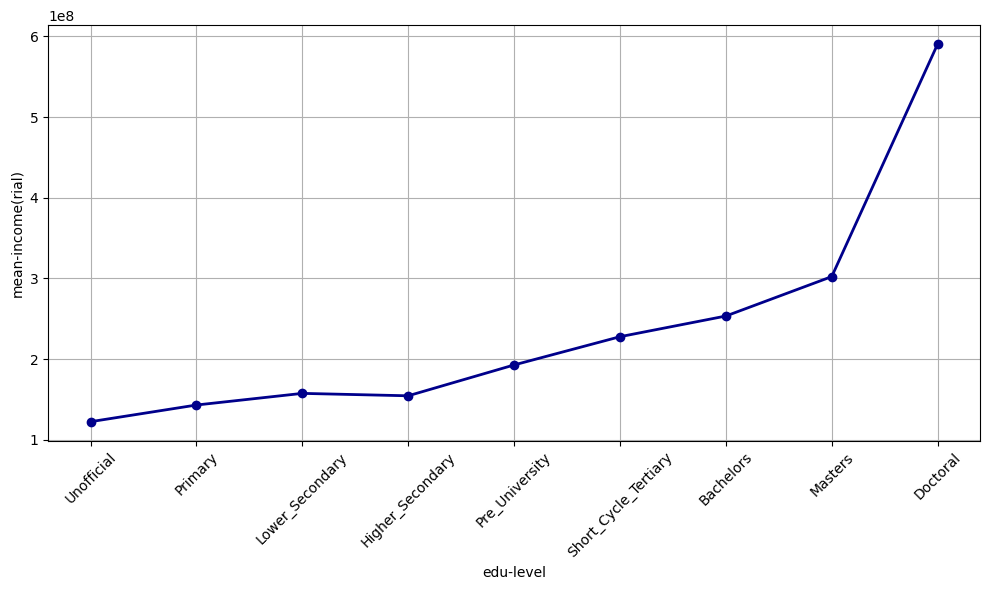

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

# لیست مرتب‌شده سطح تحصیلات
valid_levels = [
    "Unofficial",             
    "Primary",                
    "Lower_Secondary",        
    "Higher_Secondary",       
    "Pre_University",         
    "Short_Cycle_Tertiary",   
    "Bachelors",              
    "Masters",                
    "Doctoral"                
]

# فیلتر فقط سرپرست‌ها با سطح تحصیلات معتبر
df_1395 = members_1395[(members_1395["Member_Number"] == 1) & (members_1395["Education_Level"].isin(valid_levels))].copy()

# تبدیل به نوع مرتب Categorical
df_1395["Education_Level"] = pd.Categorical(df_1395["Education_Level"], categories=valid_levels, ordered=True)

# اضافه کردن درآمد سرپرست‌ها از hhinc
df_1395 = df_1395.merge(
    hhinc_1395[hhinc_1395["Member_Number"] == 1][["ID", "Income"]],
    on="ID",
    how="left"
)
print(df_1395["Income"].isna().sum())
print((df_1395["Income"] == 0).sum())

print(df_1395.shape)

# حذف ردیف‌هایی که درآمد ندارن
df_1395 = df_1395.dropna(subset=["Income"])
print((df_1395["Income"] == 0).sum())

print(df_1395.shape)

# محاسبه میانگین درآمد برای هر سطح تحصیل
mean_income_1395 = df_1395.groupby("Education_Level")["Income"].mean().reindex(valid_levels)

# 📈 رسم نمودار
plt.figure(figsize=(10, 6))
plt.plot(mean_income_1395.index, mean_income_1395.values, marker='o', color='darkblue', linewidth=2)
plt.xlabel("edu-level")
plt.ylabel("mean-income(rial)")
plt.title("")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Urban-rural income models



---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.083
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     1248.
Date:                Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                        02:28:10   Log-Likelihood:            -5.5273e+05
No. Observations:               27449   AIC:                         1.105e+06
Df Residuals:                   27446   BIC:                         1.105e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   9.246e+07   1.

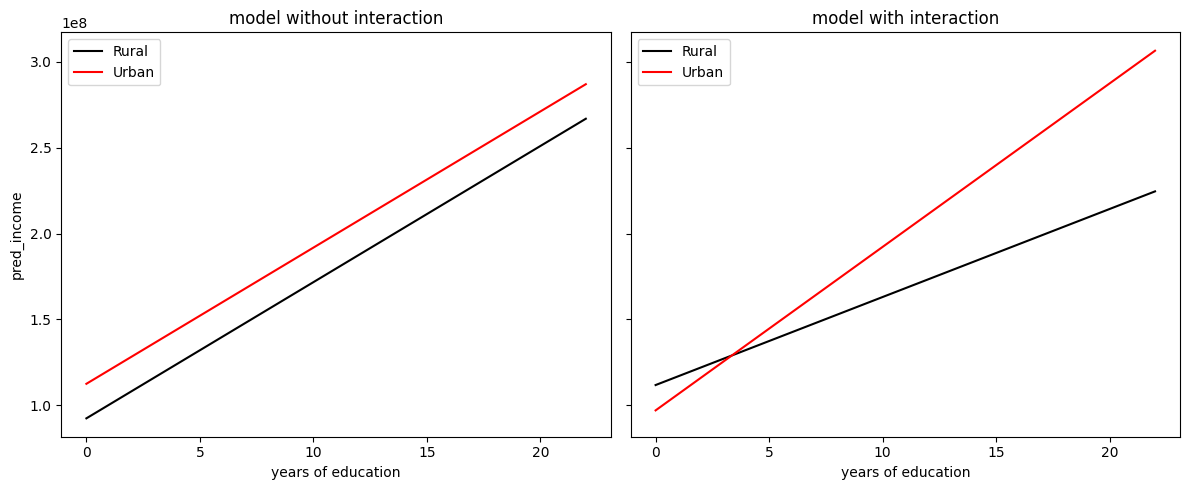

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# ----------------------
# 1. نگاشت سطح تحصیلات به سال تحصیل
# ----------------------
edu_map = {
    "Unofficial": 0,
    "Primary": 5,
    "Lower_Secondary": 8,
    "Higher_Secondary": 12,
    "Pre_University": 13,
    "Short_Cycle_Tertiary": 14,
    "Bachelors": 16,
    "Masters": 18,
    "Doctoral": 22
}

# فیلتر فقط سرپرست‌ها با سطح تحصیلات معتبر
df = members_1395[(members_1395["Member_Number"] == 1) & 
             (members_1395["Education_Level"].isin(valid_levels))].copy()

# افزودن سال تحصیل
# افزودن سال تحصیل و تبدیل به عدد
df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)


# اضافه کردن درآمد
df = df.merge(
    hhinc_1395[hhinc_1395["Member_Number"] == 1][["ID", "Income"]],
    on="ID", how="left"
)

# اضافه کردن شهری/روستایی
urban_rural = table_1395[["ID", "Urban_Rural"]].drop_duplicates()
df = df.merge(urban_rural, on="ID", how="left")

# حذف ردیف‌هایی که درآمد ندارند
df = df.dropna(subset=["Income"])

# تبدیل Urban_Rural به ۰ و ۱
df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

# ----------------------
# 2. مدل‌سازی
# ----------------------
# مدل بدون تعامل
model_no_inter = smf.ols("Income ~ Years_Edu + Urban", data=df).fit()

# مدل با تعامل
model_inter = smf.ols("Income ~ Years_Edu * Urban", data=df).fit()

print("\n---- مدل بدون تعامل ----")
print(model_no_inter.summary())

print("\n---- مدل با تعامل ----")
print(model_inter.summary())

# ----------------------
# 3. رسم نمودار
# ----------------------
# بازه تحصیلات برای پیش‌بینی
years_range = np.linspace(df["Years_Edu"].min(), df["Years_Edu"].max(), 100)

plot_df = pd.DataFrame({
    "Years_Edu": np.tile(years_range, 2),
    "Urban": np.repeat([0, 1], len(years_range))
})

# پیش‌بینی
plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
plot_df["pred_inter"] = model_inter.predict(plot_df)

# رسم
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# بدون تعامل
for u, color, label in [(0, "black", "Rural"), (1, "red", "Urban")]:
    subset = plot_df[plot_df["Urban"] == u]
    axes[0].plot(subset["Years_Edu"], subset["pred_no_inter"], color=color, label=label)

axes[0].set_title("model without interaction")
axes[0].set_xlabel("years of education")
axes[0].set_ylabel("pred_income")
axes[0].legend()

# با تعامل
for u, color, label in [(0, "black", "Rural"), (1, "red", "Urban")]:
    subset = plot_df[plot_df["Urban"] == u]
    axes[1].plot(subset["Years_Edu"], subset["pred_inter"], color=color, label=label)

axes[1].set_title("model with interaction")
axes[1].set_xlabel("years of education")
axes[1].legend()

plt.tight_layout()
plt.show()


## Urban-rural models across years



=== پردازش سال 1393 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.069
Model:                            OLS   Adj. R-squared:                  0.069
Method:                 Least Squares   F-statistic:                     1023.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        21:04:23   Log-Likelihood:            -5.4743e+05
No. Observations:               27600   AIC:                         1.095e+06
Df Residuals:                   27597   BIC:                         1.095e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
I

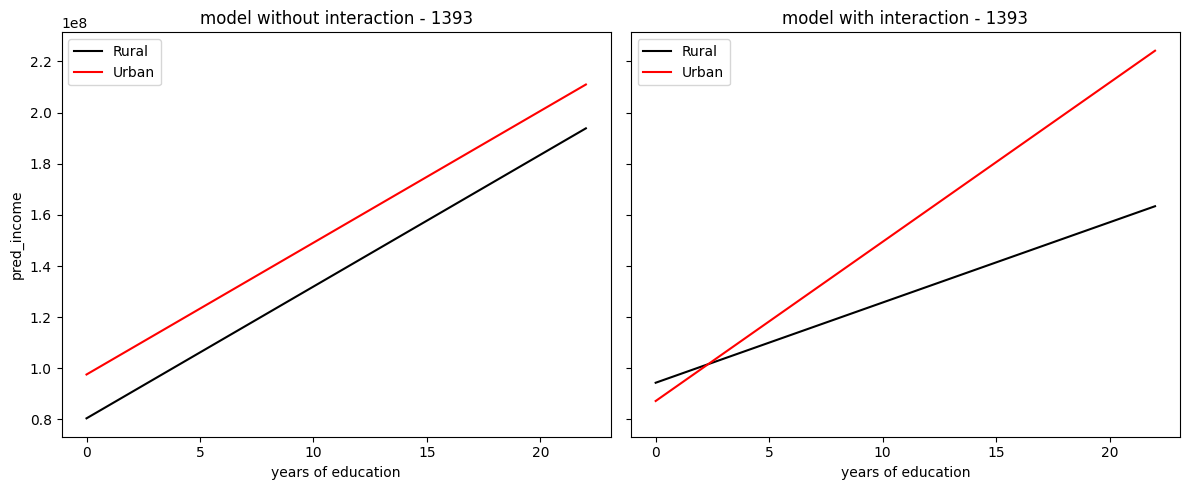


=== پردازش سال 1394 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.069
Model:                            OLS   Adj. R-squared:                  0.069
Method:                 Least Squares   F-statistic:                     1016.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        21:04:47   Log-Likelihood:            -5.5088e+05
No. Observations:               27524   AIC:                         1.102e+06
Df Residuals:                   27521   BIC:                         1.102e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
I

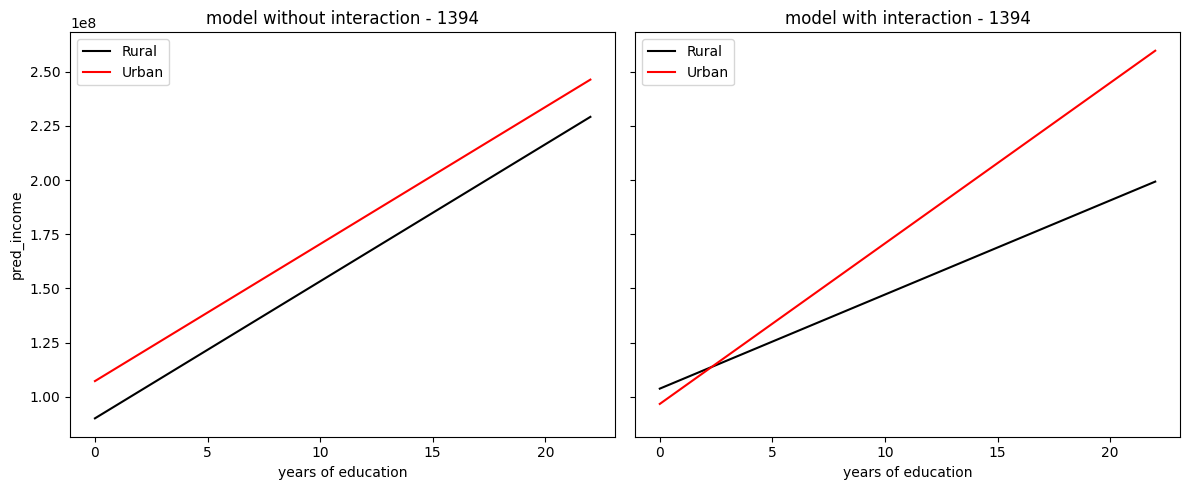


=== پردازش سال 1395 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.083
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     1248.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        21:05:13   Log-Likelihood:            -5.5273e+05
No. Observations:               27449   AIC:                         1.105e+06
Df Residuals:                   27446   BIC:                         1.105e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
I

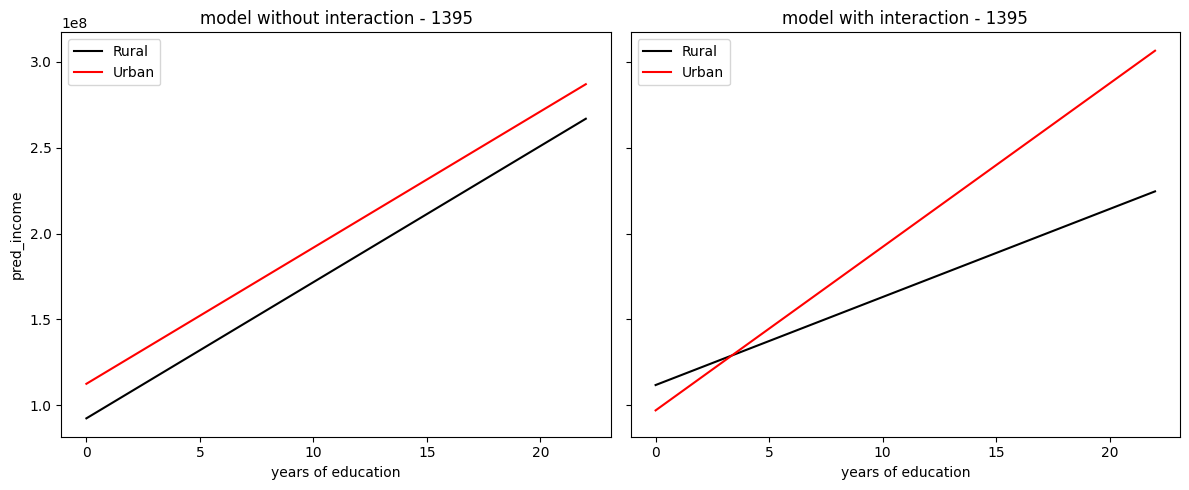


=== پردازش سال 1396 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.115
Model:                            OLS   Adj. R-squared:                  0.115
Method:                 Least Squares   F-statistic:                     1788.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        21:05:32   Log-Likelihood:            -5.5502e+05
No. Observations:               27576   AIC:                         1.110e+06
Df Residuals:                   27573   BIC:                         1.110e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
I

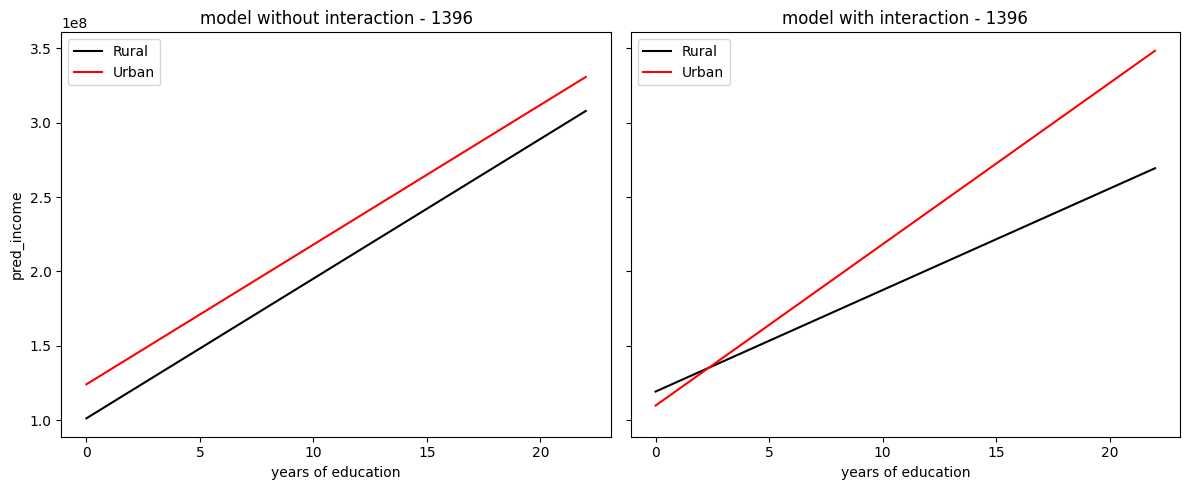


=== پردازش سال 1397 ===
⚠ خطا در پردازش سال 1397: File is not a zip file

=== پردازش سال 1398 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.090
Model:                            OLS   Adj. R-squared:                  0.090
Method:                 Least Squares   F-statistic:                     1425.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        21:05:54   Log-Likelihood:            -5.9417e+05
No. Observations:               28929   AIC:                         1.188e+06
Df Residuals:                   28926   BIC:                         1.188e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------

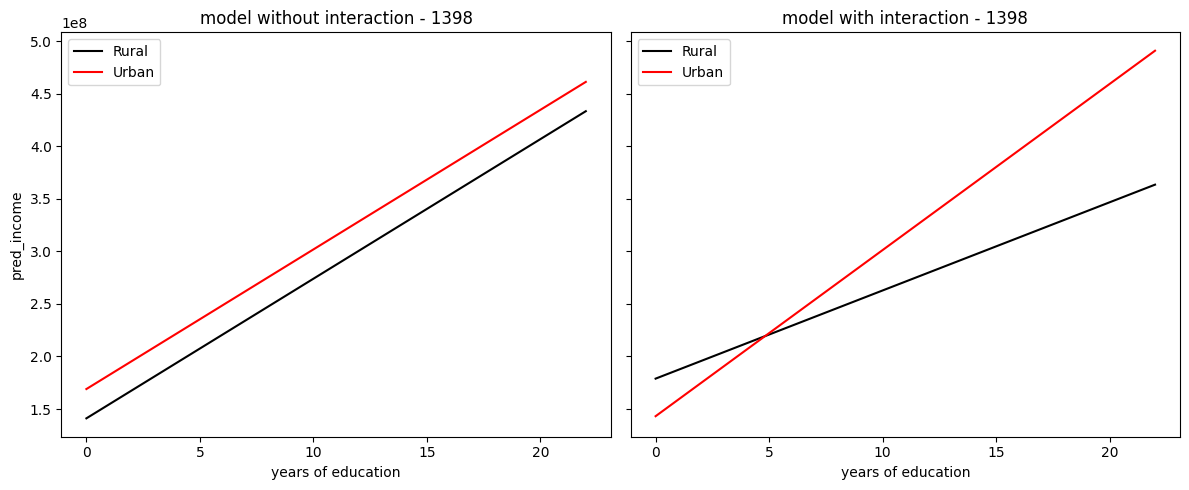


=== پردازش سال 1399 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.064
Model:                            OLS   Adj. R-squared:                  0.064
Method:                 Least Squares   F-statistic:                     993.3
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        21:06:16   Log-Likelihood:            -6.0973e+05
No. Observations:               28875   AIC:                         1.219e+06
Df Residuals:                   28872   BIC:                         1.219e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
I

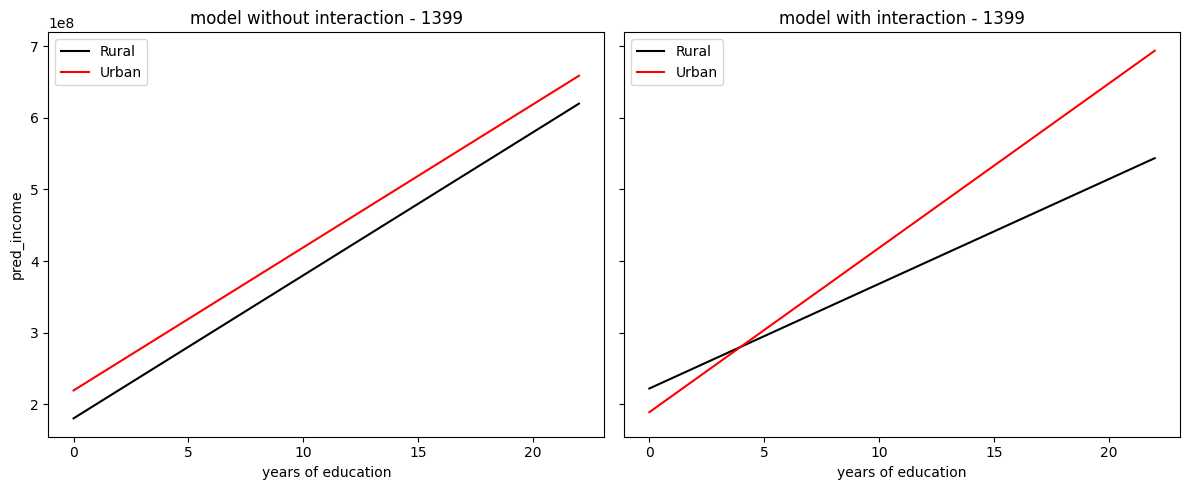


=== پردازش سال 1400 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.063
Model:                            OLS   Adj. R-squared:                  0.063
Method:                 Least Squares   F-statistic:                     988.2
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        21:06:38   Log-Likelihood:            -6.3233e+05
No. Observations:               29377   AIC:                         1.265e+06
Df Residuals:                   29374   BIC:                         1.265e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
I

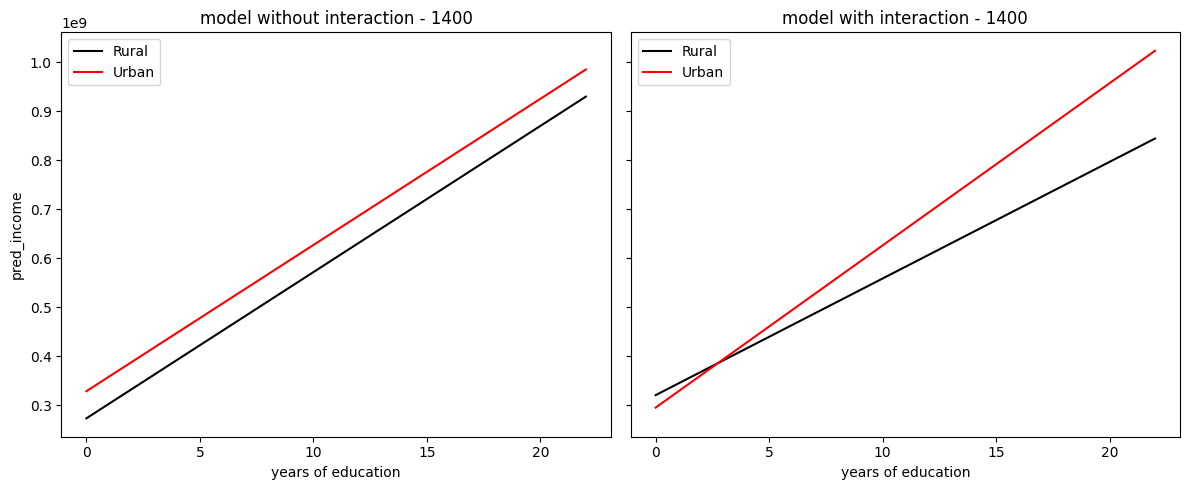


=== پردازش سال 1401 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.052
Model:                            OLS   Adj. R-squared:                  0.052
Method:                 Least Squares   F-statistic:                     809.0
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        21:06:57   Log-Likelihood:            -6.3997e+05
No. Observations:               29207   AIC:                         1.280e+06
Df Residuals:                   29204   BIC:                         1.280e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
I

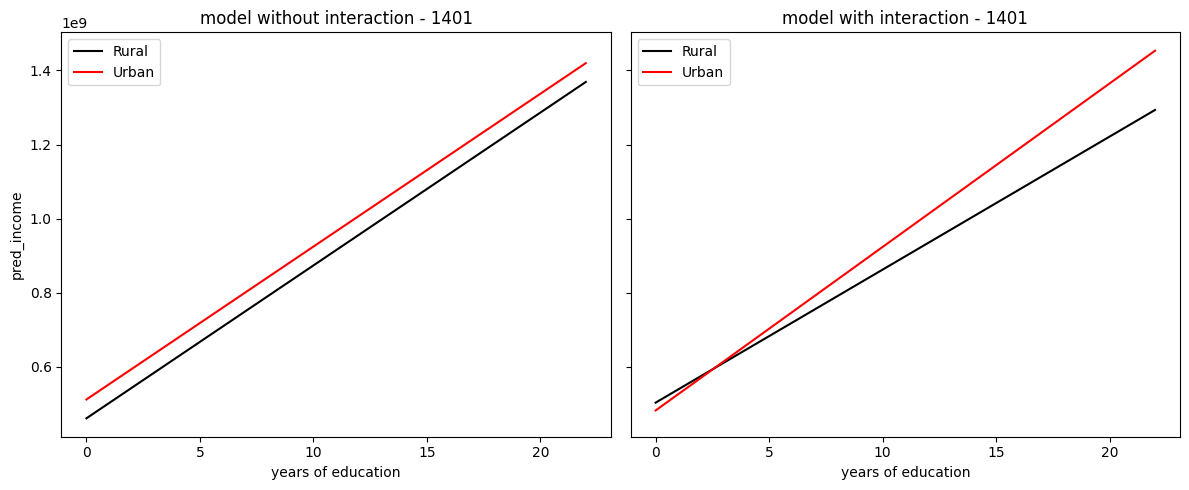


=== پردازش سال 1402 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.046
Model:                            OLS   Adj. R-squared:                  0.046
Method:                 Least Squares   F-statistic:                     694.0
Date:                Fri, 26 Sep 2025   Prob (F-statistic):          3.72e-295
Time:                        21:07:19   Log-Likelihood:            -6.4687e+05
No. Observations:               29050   AIC:                         1.294e+06
Df Residuals:                   29047   BIC:                         1.294e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
I

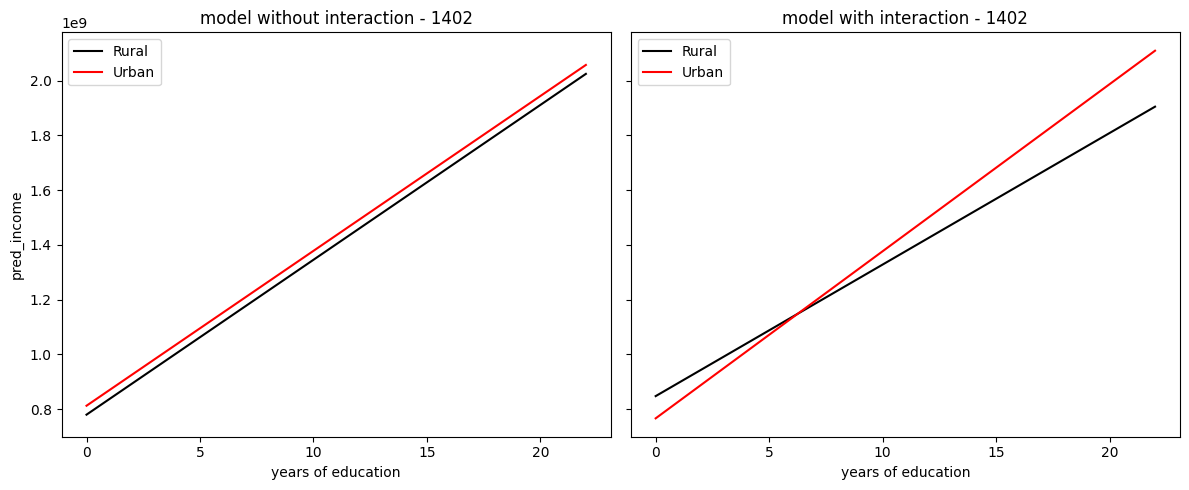


=== پردازش سال 1403 ===
⚠ خطا در پردازش سال 1403: No objects to concatenate


In [ ]:
for year in range(1393, 1404):
    print(f"\n=== پردازش سال {year} ===")
    try:
        # ---------- بارگذاری داده‌ها ----------
        hbsir.setup(years=[year])
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")

        hhinc = hbsir.load_table("Members_Total_Income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # ---------- پردازش ----------
        df = members[(members["Member_Number"] == 1) & 
                     (members["Education_Level"].isin(valid_levels))].copy()
        df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)

        df = df.merge(
            hhinc[hhinc["Member_Number"] == 1][["ID", "Income"]],
            on="ID", how="left"
        )

        urban_rural = table[["ID", "Urban_Rural"]].drop_duplicates()
        df = df.merge(urban_rural, on="ID", how="left")

        df = df.dropna(subset=["Income"])
        df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

        # ---------- مدل ----------
        model_no_inter = smf.ols("Income ~ Years_Edu + Urban", data=df).fit()
        model_inter = smf.ols("Income ~ Years_Edu * Urban", data=df).fit()

        print("\n---- مدل بدون تعامل ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل ----")
        print(model_inter.summary())

        # ---------- نمودار ----------
        years_range = np.linspace(df["Years_Edu"].min(), df["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, 2),
            "Urban": np.repeat([0, 1], len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"] = model_inter.predict(plot_df)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for u, color, label in [(0, "black", "Rural"), (1, "red", "Urban")]:
            subset = plot_df[plot_df["Urban"] == u]
            axes[0].plot(subset["Years_Edu"], subset["pred_no_inter"], color=color, label=label)
            axes[1].plot(subset["Years_Edu"], subset["pred_inter"], color=color, label=label)

        axes[0].set_title(f"model without interaction - {year}")
        axes[0].set_xlabel("years of education")
        axes[0].set_ylabel("pred_income")
        axes[0].legend()

        axes[1].set_title(f"model with interaction - {year}")
        axes[1].set_xlabel("years of education")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue


## Gender interaction models



=== پردازش سال 1393 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.071
Model:                            OLS   Adj. R-squared:                  0.071
Method:                 Least Squares   F-statistic:                     1061.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        22:50:15   Log-Likelihood:            -5.4740e+05
No. Observations:               27600   AIC:                         1.095e+06
Df Residuals:                   27597   BIC:                         1.095e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

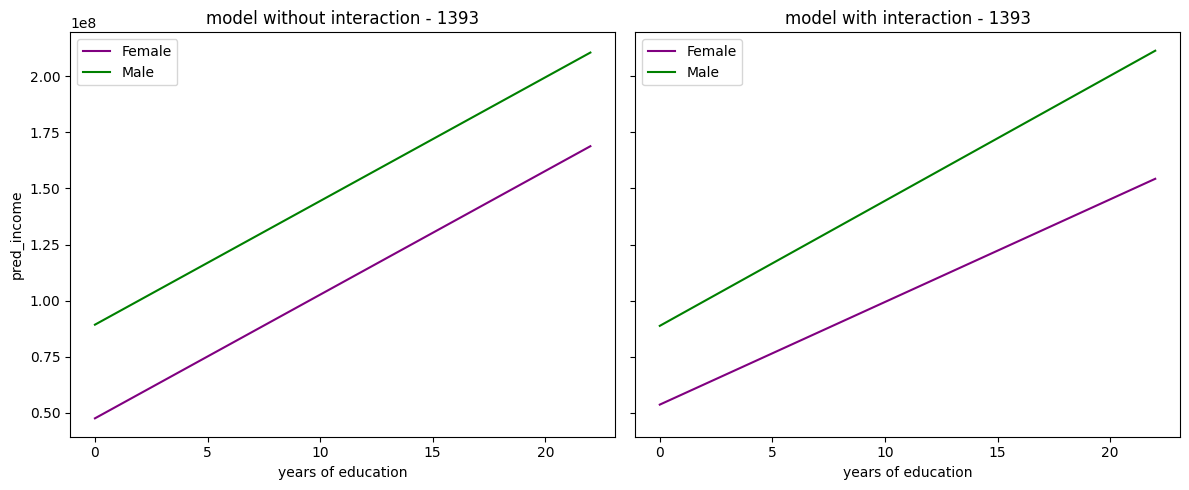


=== پردازش سال 1394 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.072
Model:                            OLS   Adj. R-squared:                  0.072
Method:                 Least Squares   F-statistic:                     1064.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        22:50:40   Log-Likelihood:            -5.5084e+05
No. Observations:               27524   AIC:                         1.102e+06
Df Residuals:                   27521   BIC:                         1.102e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

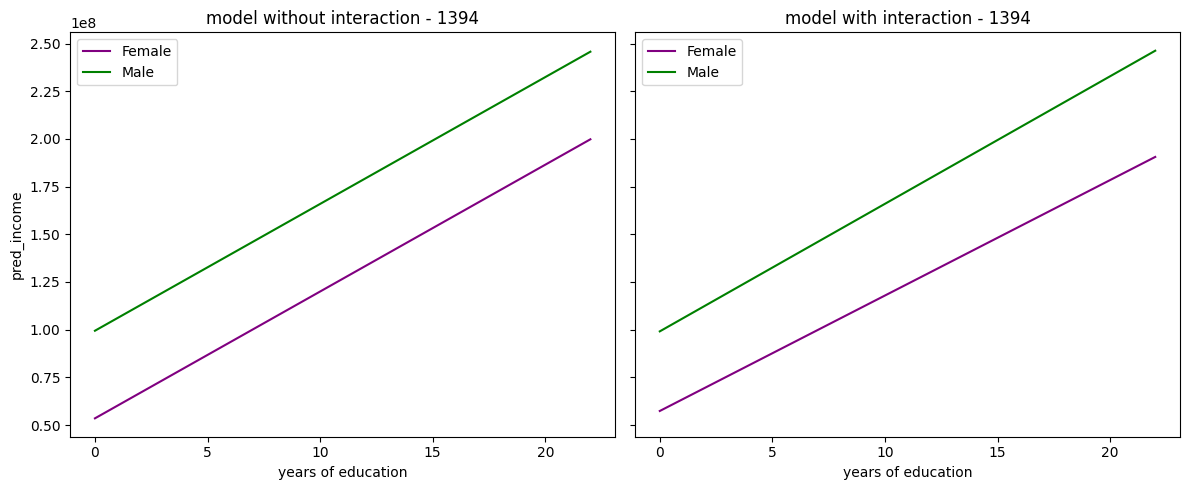


=== پردازش سال 1395 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.088
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     1322.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        22:51:06   Log-Likelihood:            -5.5266e+05
No. Observations:               27449   AIC:                         1.105e+06
Df Residuals:                   27446   BIC:                         1.105e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

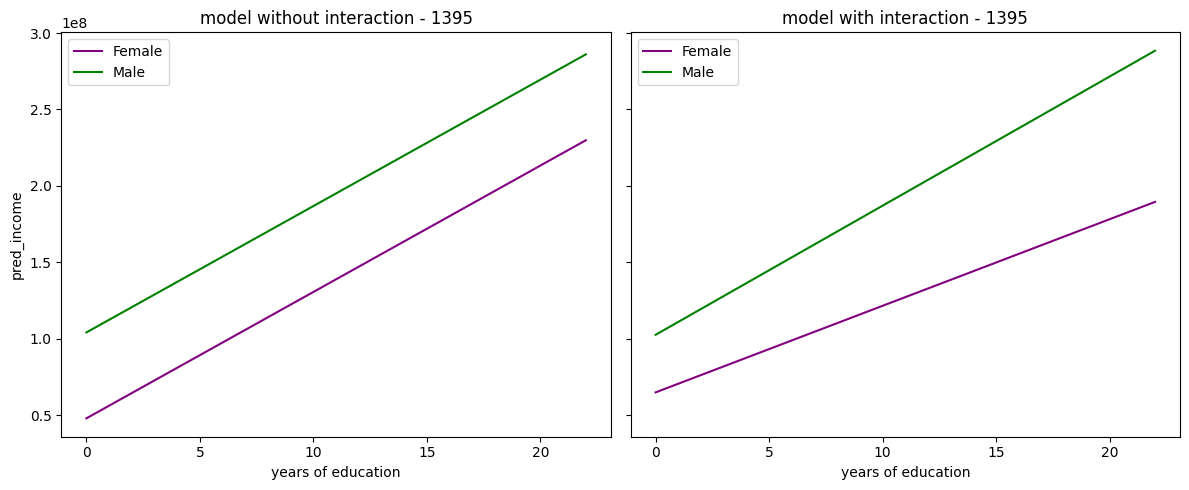


=== پردازش سال 1396 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.117
Model:                            OLS   Adj. R-squared:                  0.117
Method:                 Least Squares   F-statistic:                     1826.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        22:51:25   Log-Likelihood:            -5.5499e+05
No. Observations:               27576   AIC:                         1.110e+06
Df Residuals:                   27573   BIC:                         1.110e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

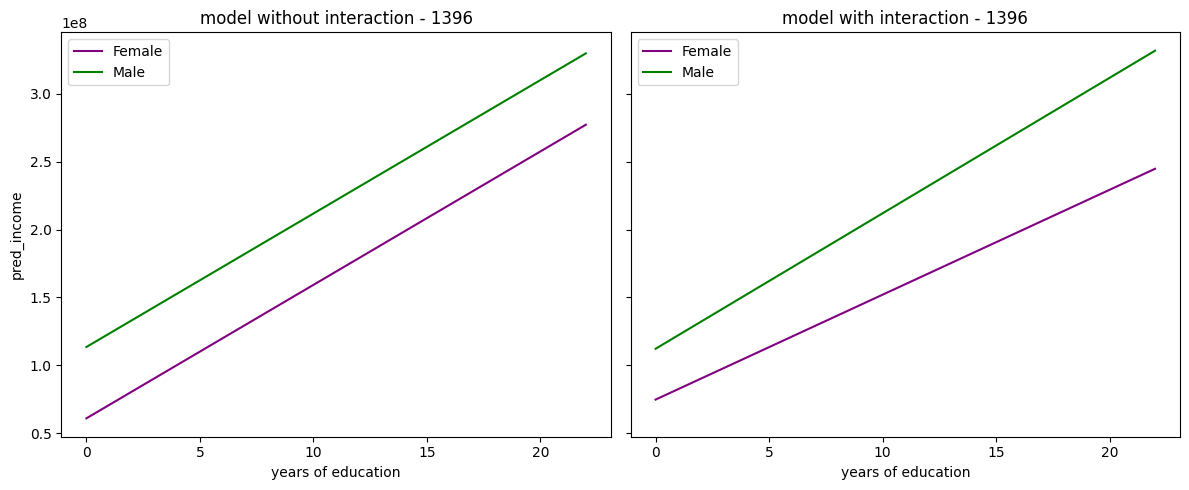


=== پردازش سال 1397 ===
⚠ خطا در پردازش سال 1397: File is not a zip file

=== پردازش سال 1398 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.096
Model:                            OLS   Adj. R-squared:                  0.096
Method:                 Least Squares   F-statistic:                     1532.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        22:51:49   Log-Likelihood:            -5.9408e+05
No. Observations:               28929   AIC:                         1.188e+06
Df Residuals:                   28926   BIC:                         1.188e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975

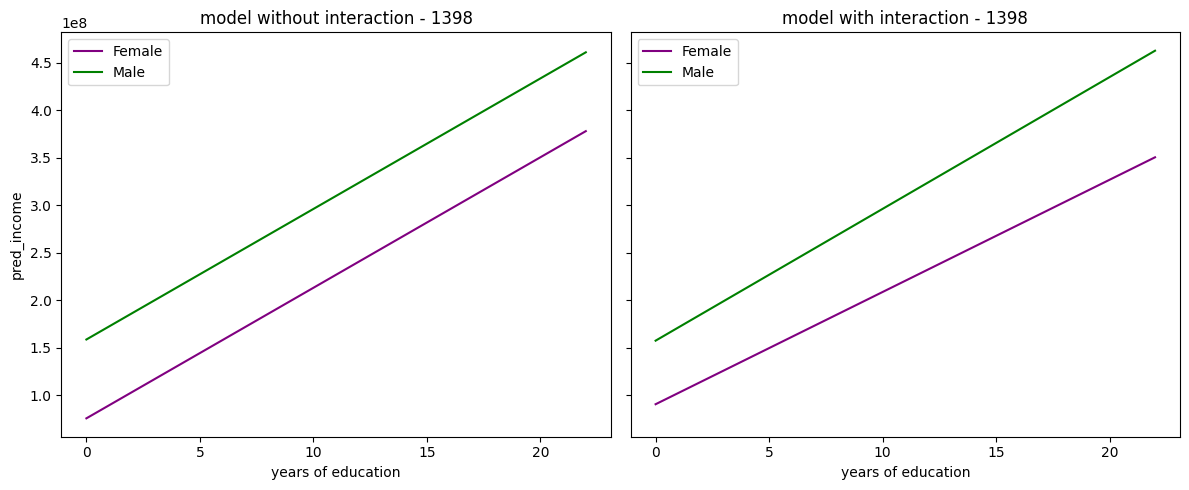


=== پردازش سال 1399 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.069
Model:                            OLS   Adj. R-squared:                  0.069
Method:                 Least Squares   F-statistic:                     1067.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        22:52:10   Log-Likelihood:            -6.0966e+05
No. Observations:               28875   AIC:                         1.219e+06
Df Residuals:                   28872   BIC:                         1.219e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

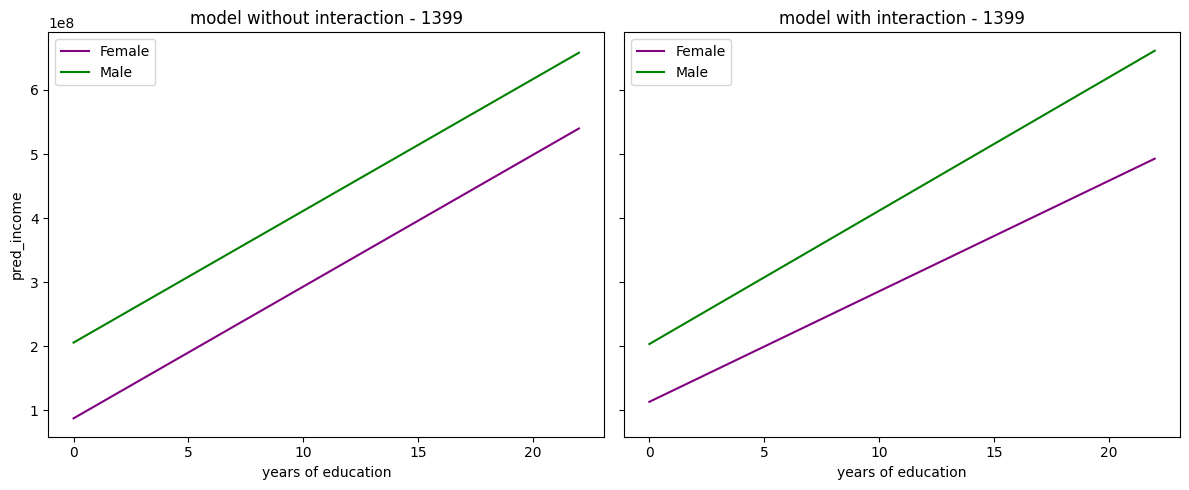


=== پردازش سال 1400 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.069
Model:                            OLS   Adj. R-squared:                  0.069
Method:                 Least Squares   F-statistic:                     1091.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        22:52:33   Log-Likelihood:            -6.3223e+05
No. Observations:               29377   AIC:                         1.264e+06
Df Residuals:                   29374   BIC:                         1.264e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

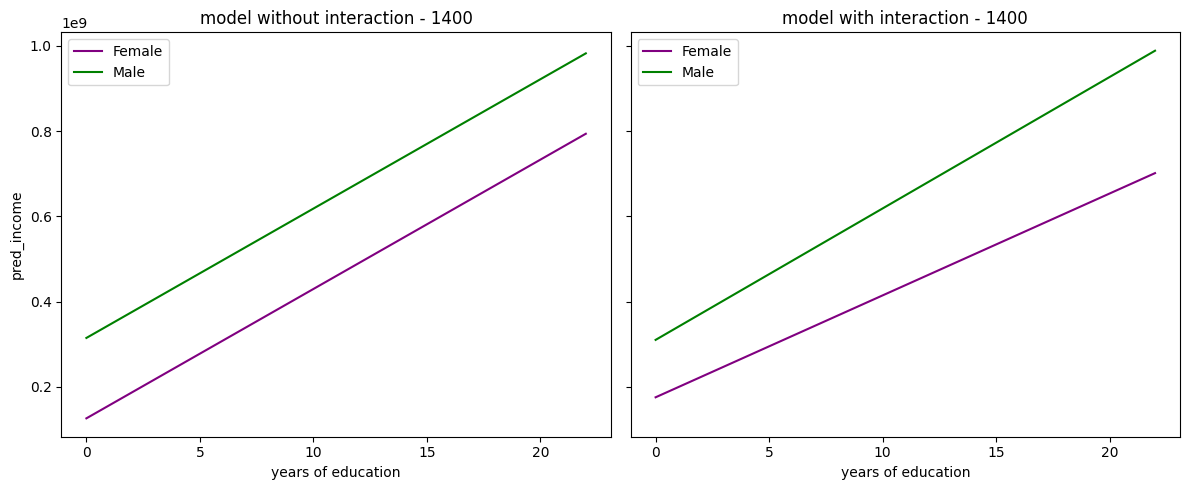


=== پردازش سال 1401 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.063
Model:                            OLS   Adj. R-squared:                  0.063
Method:                 Least Squares   F-statistic:                     981.5
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        22:52:53   Log-Likelihood:            -6.3976e+05
No. Observations:               29205   AIC:                         1.280e+06
Df Residuals:                   29202   BIC:                         1.280e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

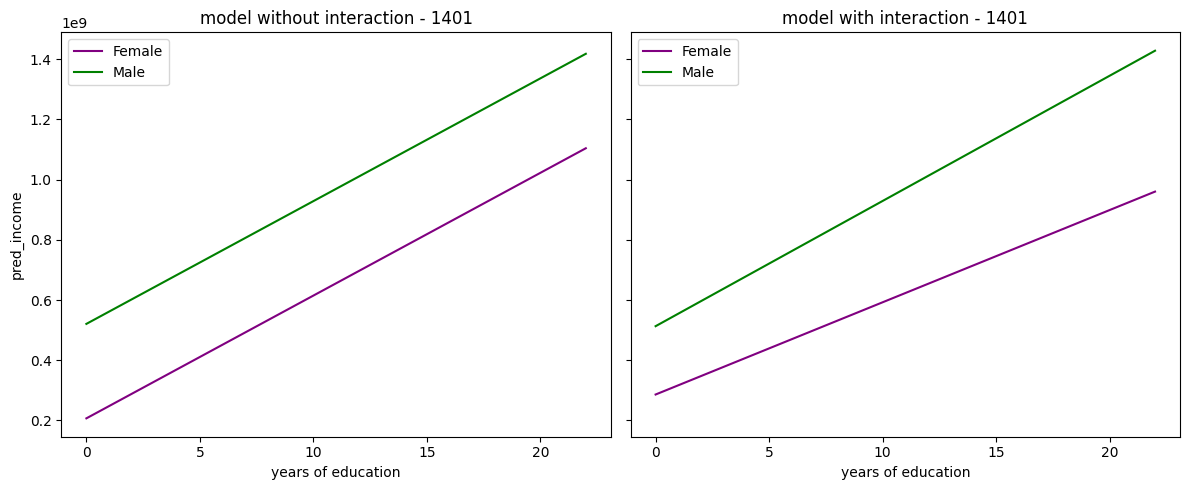


=== پردازش سال 1402 ===

---- مدل بدون تعامل ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.060
Model:                            OLS   Adj. R-squared:                  0.060
Method:                 Least Squares   F-statistic:                     925.9
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        22:53:14   Log-Likelihood:            -6.4665e+05
No. Observations:               29050   AIC:                         1.293e+06
Df Residuals:                   29047   BIC:                         1.293e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

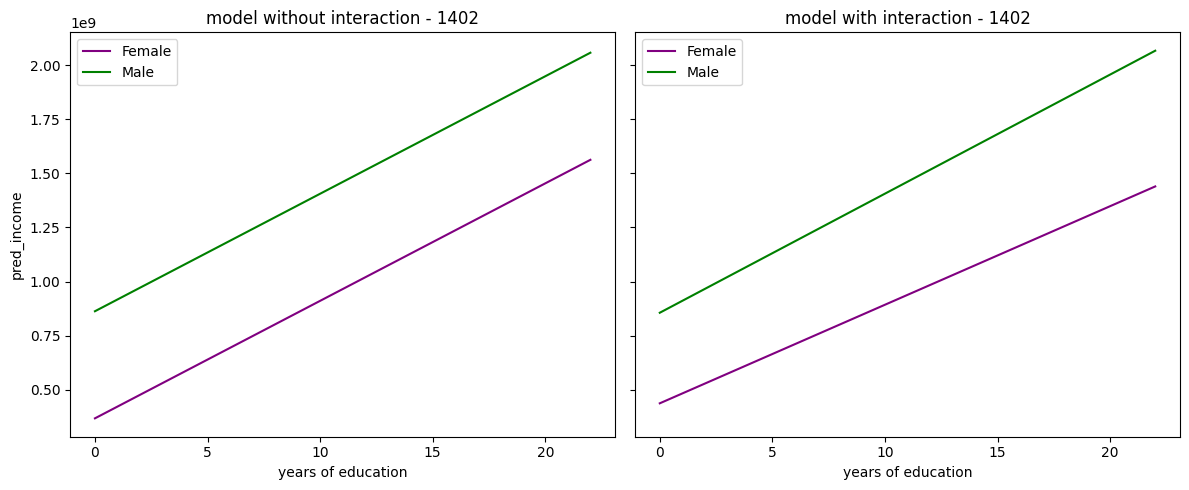

In [ ]:
for year in range(1393, 1403):
    print(f"\n=== پردازش سال {year} ===")
    try:
        # ---------- بارگذاری داده‌ها ----------
        hbsir.setup(years=[year])
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")  # دیگه استفاده نمیشه، ولی نگه داشتم اگر لازم شد

        hhinc = hbsir.load_table("Members_Total_Income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # ---------- پردازش ----------
        df = members[(members["Member_Number"] == 1) &
                     (members["Education_Level"].isin(valid_levels))].copy()
        df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)

        # اضافه کردن درآمد
        df = df.merge(
            hhinc[hhinc["Member_Number"] == 1][["ID", "Income"]],
            on="ID", how="left"
        )

        # ستون جنسیت: فرض بر اینه که ستون Gender در members هست
        # Male -> 1, Female -> 0
        df["Gender_Binary"] = df["Sex"].apply(lambda x: 1 if str(x).lower() == "male" else 0)

        # حذف ردیف‌های بدون درآمد یا بدون جنسیت
        df = df.dropna(subset=["Income", "Gender_Binary"])

        # ---------- مدل ----------
        model_no_inter = smf.ols("Income ~ Years_Edu + Gender_Binary", data=df).fit()
        model_inter = smf.ols("Income ~ Years_Edu * Gender_Binary", data=df).fit()

        print("\n---- مدل بدون تعامل ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل ----")
        print(model_inter.summary())

        # ---------- نمودار ----------
        years_range = np.linspace(df["Years_Edu"].min(), df["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, 2),
            "Gender_Binary": np.repeat([0, 1], len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"] = model_inter.predict(plot_df)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for g, color, label in [(0, "purple", "Female"), (1, "green", "Male")]:
            subset = plot_df[plot_df["Gender_Binary"] == g]
            axes[0].plot(subset["Years_Edu"], subset["pred_no_inter"], color=color, label=label)
            axes[1].plot(subset["Years_Edu"], subset["pred_inter"], color=color, label=label)

        axes[0].set_title(f"model without interaction - {year}")
        axes[0].set_xlabel("years of education")
        axes[0].set_ylabel("pred_income")
        axes[0].legend()

        axes[1].set_title(f"model with interaction - {year}")
        axes[1].set_xlabel("years of education")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue


## PCA welfare index and urban-rural models



=== پردازش سال 1393 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     26.17
Date:                Fri, 26 Sep 2025   Prob (F-statistic):           4.40e-12
Time:                        23:52:08   Log-Likelihood:                -43558.
No. Observations:               27619   AIC:                         8.712e+04
Df Residuals:                   27616   BIC:                         8.715e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

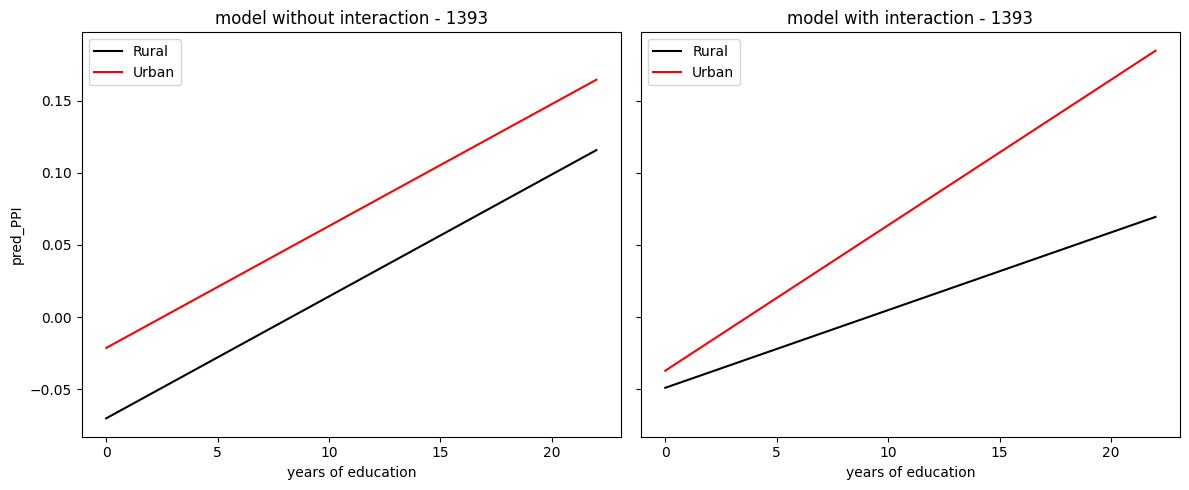


=== پردازش سال 1394 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.109
Model:                            OLS   Adj. R-squared:                  0.109
Method:                 Least Squares   F-statistic:                     1681.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        23:53:18   Log-Likelihood:                -37328.
No. Observations:               27543   AIC:                         7.466e+04
Df Residuals:                   27540   BIC:                         7.469e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

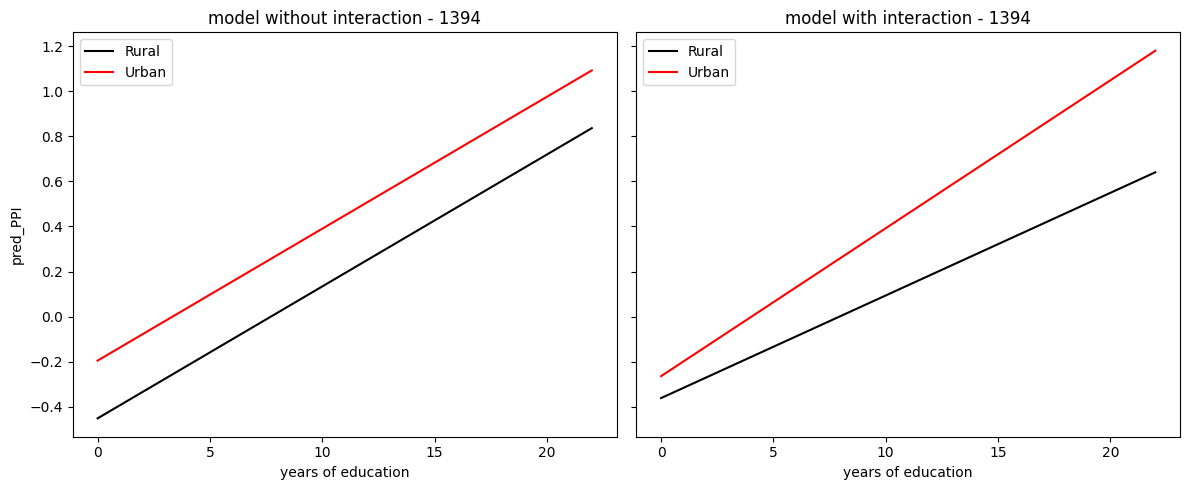


=== پردازش سال 1395 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.023
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     325.5
Date:                Fri, 26 Sep 2025   Prob (F-statistic):          1.90e-140
Time:                        23:54:30   Log-Likelihood:                -42159.
No. Observations:               27483   AIC:                         8.432e+04
Df Residuals:                   27480   BIC:                         8.435e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

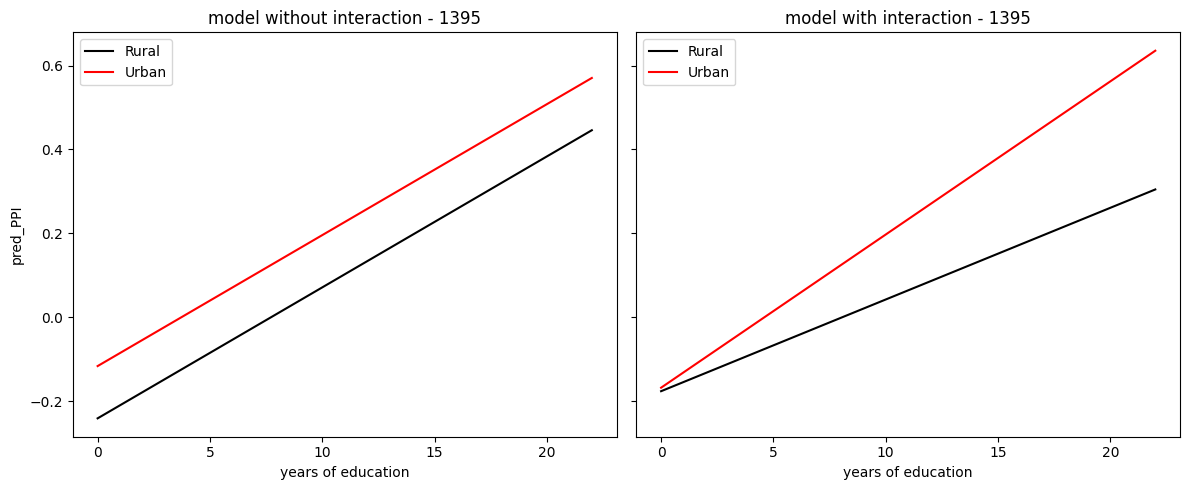


=== پردازش سال 1396 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.159
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     2615.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        23:55:28   Log-Likelihood:                -35621.
No. Observations:               27600   AIC:                         7.125e+04
Df Residuals:                   27597   BIC:                         7.127e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

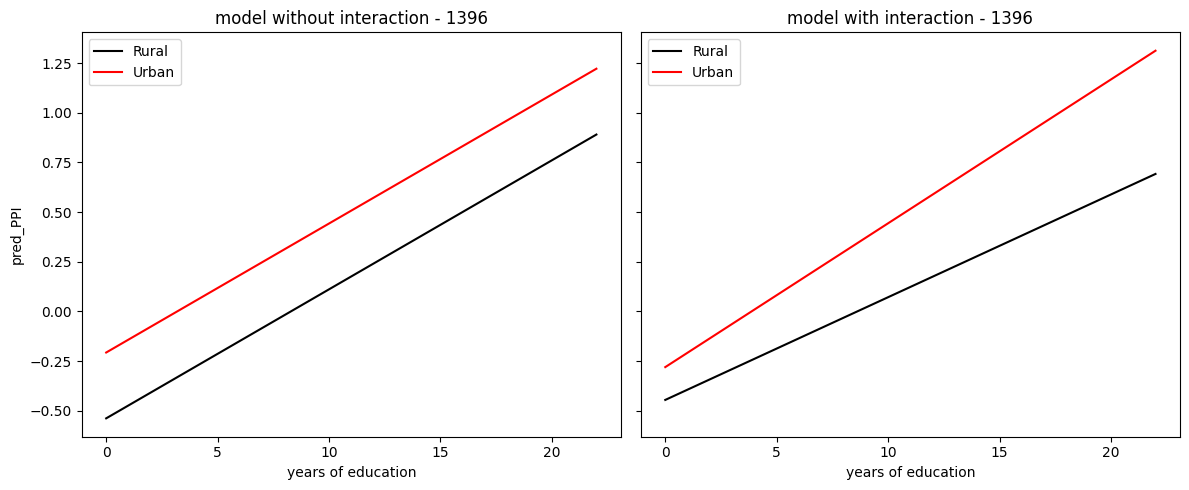


=== پردازش سال 1397 ===
⚠ خطا در پردازش سال 1397: File is not a zip file

=== پردازش سال 1398 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     128.4
Date:                Fri, 26 Sep 2025   Prob (F-statistic):           2.96e-56
Time:                        23:56:31   Log-Likelihood:                -44472.
No. Observations:               28952   AIC:                         8.895e+04
Df Residuals:                   28949   BIC:                         8.898e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.0

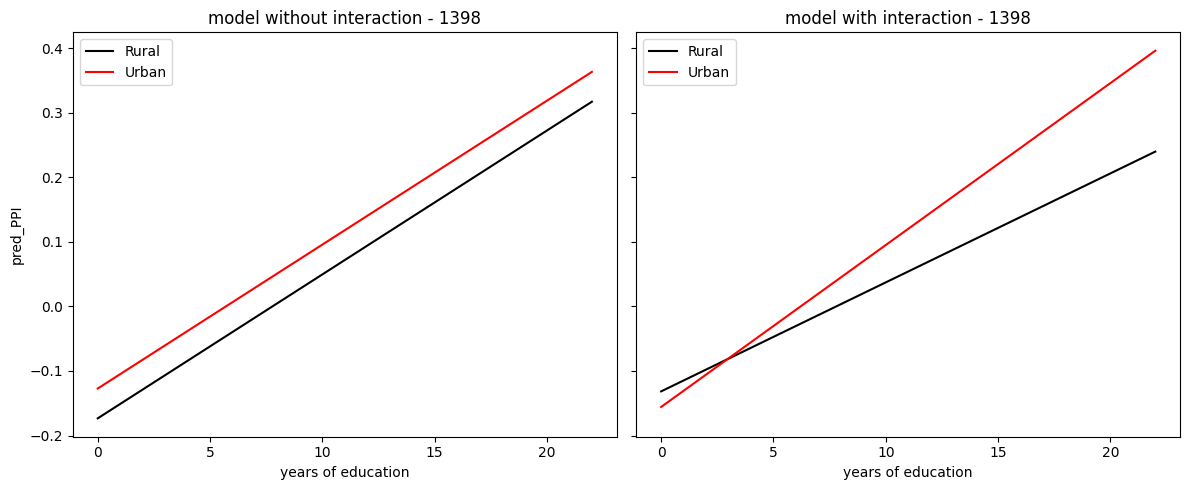


=== پردازش سال 1399 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.022
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     320.4
Date:                Fri, 26 Sep 2025   Prob (F-statistic):          2.30e-138
Time:                        23:57:32   Log-Likelihood:                -43562.
No. Observations:               28894   AIC:                         8.713e+04
Df Residuals:                   28891   BIC:                         8.716e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

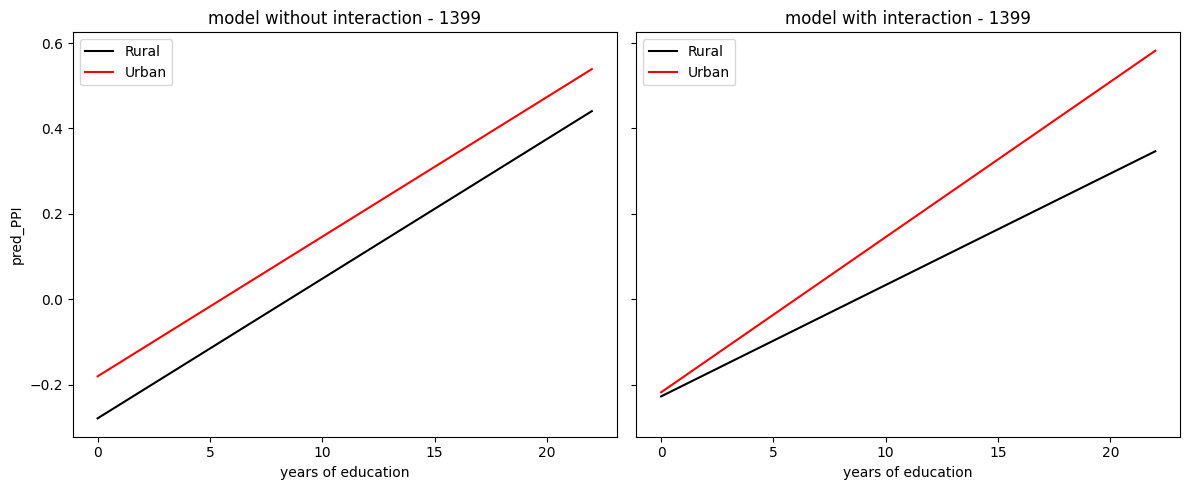


=== پردازش سال 1400 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.136
Model:                            OLS   Adj. R-squared:                  0.136
Method:                 Least Squares   F-statistic:                     2318.
Date:                Fri, 26 Sep 2025   Prob (F-statistic):               0.00
Time:                        23:58:34   Log-Likelihood:                -37836.
No. Observations:               29397   AIC:                         7.568e+04
Df Residuals:                   29394   BIC:                         7.570e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

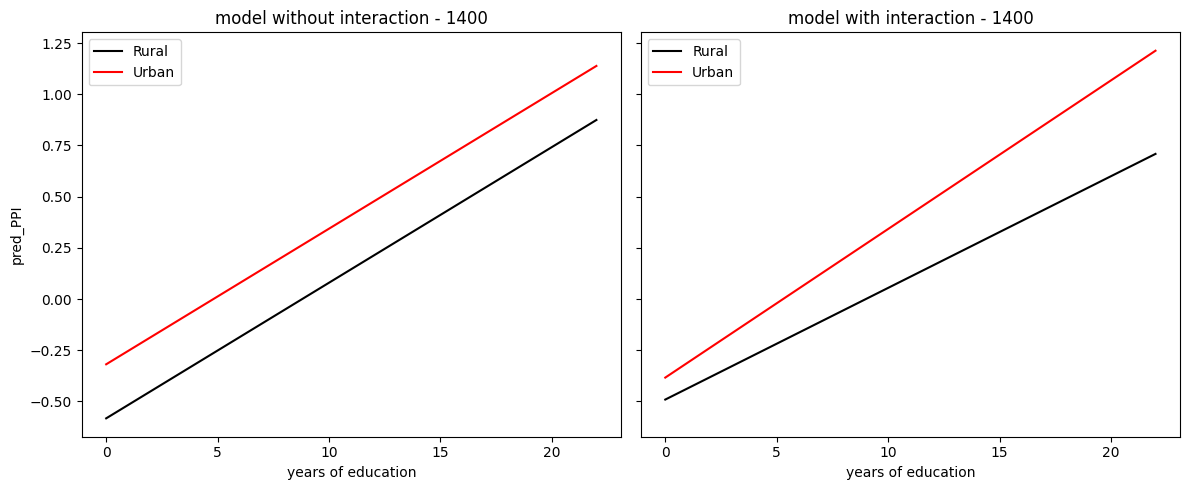


=== پردازش سال 1401 ===


C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20240\2514516298.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)
C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20240\2514516298.py:94: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})



---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     510.0
Date:                Fri, 26 Sep 2025   Prob (F-statistic):          1.97e-218
Time:                        23:59:30   Log-Likelihood:                -42393.
No. Observations:               29240   AIC:                         8.479e+04
Df Residuals:                   29237   BIC:                         8.482e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Inter

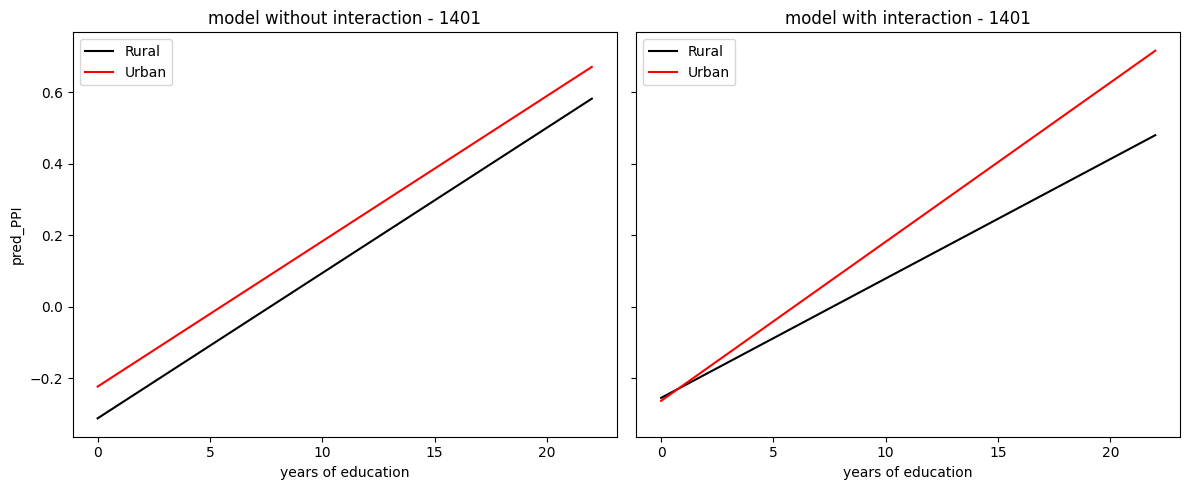


=== پردازش سال 1402 ===


C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20240\2514516298.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)
C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20240\2514516298.py:94: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})



---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.654
Date:                Sat, 27 Sep 2025   Prob (F-statistic):              0.191
Time:                        00:00:33   Log-Likelihood:                -45093.
No. Observations:               29079   AIC:                         9.019e+04
Df Residuals:                   29076   BIC:                         9.022e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Inter

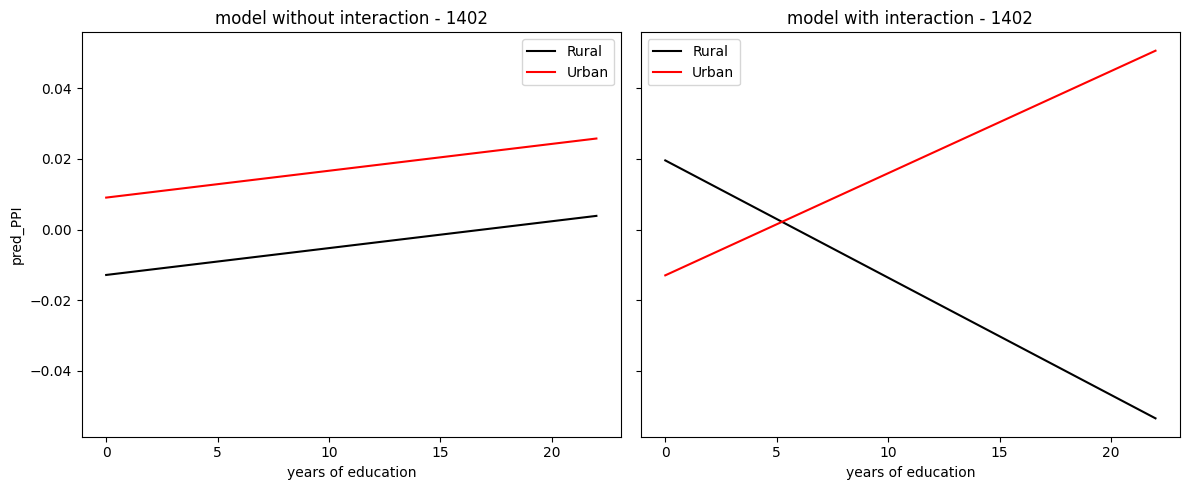

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

import hbsir
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ---------------------------
# Helpers
# ---------------------------
def winsorize(s, low_q=0.01, high_q=0.99):
    lo, hi = s.quantile(low_q), s.quantile(high_q)
    return s.clip(lower=lo, upper=hi)

def safe_log_series(s, eps=1.0):
    s = pd.to_numeric(s, errors="coerce").astype("float64")
    s = s.replace([np.inf, -np.inf], np.nan)
    s = s.clip(lower=eps)
    return np.log(s)

from pandas.api.types import is_numeric_dtype
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def cast_numeric(df: pd.DataFrame) -> pd.DataFrame:
    """هر ستونی که عددی باشد را به float64 استاندارد تبدیل می‌کند (رفع UInt8Dtype و ...)."""
    for c in df.columns:
        if is_numeric_dtype(df[c]):
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
    return df

def build_ppi_for_year(year):
    """PPI (PCA) را برای هر خانوار در سالِ ورودی می‌سازد و برمی‌گرداند."""
    hbsir.setup(years=[year])

    # --- Load
    exp = hbsir.load_table("Expenditures", years=[year])
    exp = hbsir.add_attribute(exp, name="Province")
    exp = hbsir.add_attribute(exp, name="County")
    exp = hbsir.add_attribute(exp, name="Urban_Rural")

    inc = hbsir.load_table("Members_Total_Income", years=[year])
    mem = hbsir.load_table("members_properties", years=[year])

    # --- Cast numeric to float64 (fix UInt8Dtype)
    exp = cast_numeric(exp)
    inc = cast_numeric(inc)
    mem = cast_numeric(mem)

    hh_key = "ID"

    # --- Category flags
    is_food = (exp.get("Table_Name", pd.Series(index=exp.index, dtype=object)) == "food")
    is_housing = (exp.get("Table_Name", pd.Series(index=exp.index, dtype=object)) == "home")

    # --- Regional price index (Province × Urban_Rural)
    price_df = exp.dropna(subset=["Price", "Commodity_Code"]).copy()
    nat_price = price_df.groupby("Commodity_Code")["Price"].median().rename("Nat_MedPrice")
    price_df = price_df.merge(nat_price, on="Commodity_Code", how="left")
    price_df = price_df[(price_df["Nat_MedPrice"] > 0) & (price_df["Price"] > 0)]
    price_df["RelPrice"] = price_df["Price"] / price_df["Nat_MedPrice"]
    price_df["Region"] = price_df["Province"].astype(str) + " | " + price_df["Urban_Rural"].astype(str)
    reg_item_rel = (price_df.groupby(["Region", "Commodity_Code"])["RelPrice"].median().reset_index())
    reg_pindex = (reg_item_rel.groupby("Region")["RelPrice"].median()
                  .rename("Region_PriceIndex").reset_index())

    exp["Region"] = exp["Province"].astype(str) + " | " + exp["Urban_Rural"].astype(str)
    exp = exp.merge(reg_pindex, on="Region", how="left")
    exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)

    # --- Real expenditures
    exp["Use_Exp"] = exp["Net_Expenditure"].fillna(exp["Gross_Expenditure"])
    exp["Real_Exp"] = exp["Use_Exp"] / exp["Region_PriceIndex"]

    hh_exp = exp.groupby(hh_key, as_index=False).agg(
        total_exp=("Use_Exp", "sum"),
        real_total_exp=("Real_Exp", "sum"),
        food_exp=("Use_Exp", lambda s: s[is_food.loc[s.index]].sum() if len(s) else 0.0),
        housing_exp=("Use_Exp", lambda s: s[is_housing.loc[s.index]].sum() if len(s) else 0.0),
    )
    hh_exp["food_share"]   = np.where(hh_exp["total_exp"]>0, hh_exp["food_exp"]/hh_exp["total_exp"], np.nan)
    hh_exp["rent_burden"]  = np.where(hh_exp["total_exp"]>0, hh_exp["housing_exp"]/hh_exp["total_exp"], np.nan)

    # --- Real income (sum all numeric cols safely)
    
    
    hh_inc = (inc.groupby("ID", as_index=False)["Income"]
            .sum()
            .rename(columns={"Income": "income_total"}))

    hh_region = exp[[hh_key, "Region"]].drop_duplicates()
    hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})
    hh_inc = hh_inc.merge(hh_region[[hh_key, "Region_PriceIndex"]], on=hh_key, how="left")
    hh_inc["Region_PriceIndex"] = hh_inc["Region_PriceIndex"].fillna(1.0)
    hh_inc["real_income"] = hh_inc["income_total"] / hh_inc["Region_PriceIndex"]

    # --- Household size & equivalence
    size = mem.groupby(hh_key).size().rename("hh_size").reset_index()
    if "Age" in mem.columns:
        tmp = mem[[hh_key, "Age"]].copy()
        tmp["is_child"] = (pd.to_numeric(tmp["Age"], errors="coerce") < 14).astype("int")
        children = tmp.groupby(hh_key)["is_child"].sum().rename("n_children").reset_index()
        demo = size.merge(children, on=hh_key, how="left").fillna({"n_children":0})
        demo["n_adults"] = (demo["hh_size"] - demo["n_children"]).clip(lower=0)
        demo["eq_size"]  = 1 + 0.5*np.maximum(demo["n_adults"]-1, 0) + 0.3*demo["n_children"]
        demo.loc[demo["eq_size"]<=0, "eq_size"] = demo["hh_size"].replace(0,1)
    else:
        demo = size.copy()
        demo["eq_size"] = np.sqrt(np.maximum(demo["hh_size"], 1))

    # --- Merge & features
    df = hh_exp.merge(hh_inc[[hh_key, "real_income"]], on=hh_key, how="left")
    df = df.merge(demo[[hh_key, "hh_size", "eq_size"]], on=hh_key, how="left")

    df["real_exp_pc"] = df["real_total_exp"] / df["eq_size"]
    df["real_inc_pc"] = df["real_income"]    / df["eq_size"]

    # پایداری
    df["real_exp_pc"] = winsorize(pd.to_numeric(df["real_exp_pc"], errors="coerce"))
    df["real_inc_pc"] = winsorize(pd.to_numeric(df["real_inc_pc"], errors="coerce"))

    df["log_real_exp_pc"] = safe_log_series(df["real_exp_pc"], eps=1.0)
    df["log_real_inc_pc"] = safe_log_series(df["real_inc_pc"], eps=1.0)

    df["one_minus_food"] = 1 - pd.to_numeric(df["food_share"],  errors="coerce")
    df["one_minus_rent"] = 1 - pd.to_numeric(df["rent_burden"], errors="coerce")

    feature_cols = ["log_real_exp_pc", "log_real_inc_pc", "one_minus_food", "one_minus_rent"]
    X = df[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(df[feature_cols].median())

    scaler = StandardScaler()
    X_std = scaler.fit_transform(X)

    pca = PCA(n_components=1, random_state=42)
    df["PPI_pca"]   = pca.fit_transform(X_std).ravel()
    df["PPI_pca_z"] = (df["PPI_pca"] - df["PPI_pca"].mean()) / df["PPI_pca"].std(ddof=0)
    df["PPI_score"] = 100 + 15*df["PPI_pca_z"]

    geo = exp[[hh_key, "Urban_Rural", "Province"]].drop_duplicates()
    df = df.merge(geo, on=hh_key, how="left")

    return df[[hh_key, "PPI_pca_z", "PPI_score", "Urban_Rural", "Province"]].drop_duplicates()



# ---------------------------
# نگاشت تحصیلات → سال‌های تحصیل (Fallback اگر نداشتی)
# ---------------------------
# اگر قبلاً valid_levels و edu_map را تعریف کرده‌ای، همین‌ها نادیده گرفته می‌شوند.
try:
    valid_levels  # type: ignore
    edu_map       # type: ignore
except NameError:
    valid_levels = [
    "Unofficial",             
    "Primary",                
    "Lower_Secondary",        
    "Higher_Secondary",       
    "Pre_University",         
    "Short_Cycle_Tertiary",   
    "Bachelors",              
    "Masters",                
    "Doctoral"                
]
    edu_map = {
    "Unofficial": 0,
    "Primary": 5,
    "Lower_Secondary": 8,
    "Higher_Secondary": 12,
    "Pre_University": 13,
    "Short_Cycle_Tertiary": 14,
    "Bachelors": 16,
    "Masters": 18,
    "Doctoral": 22
}

# ---------------------------
# Loop: سال‌ها و مدل تعاملی با PPI
# ---------------------------
for year in range(1393, 1403):
    print(f"\n=== پردازش سال {year} ===")
    try:
        hbsir.setup(years=[year])
        # داده‌ها
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")

        hhinc = hbsir.load_table("Members_Total_Income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # ساخت PPI
        ppi_df = build_ppi_for_year(year)  # ID, PPI_pca_z, PPI_score, Urban_Rural, Province

        # فیلتر سرپرست + نگاشت تحصیلات
        df = members[(members["Member_Number"] == 1)].copy()
        # اگر Education_Level متنی‌ست:
        if "Education_Level" in df.columns:
            df = df[df["Education_Level"].isin(valid_levels)].copy()
            df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)
        else:
            # اگر ستون سال تحصیل مستقیم داری:
            if "Years_Edu" not in df.columns:
                raise ValueError("ستون Education_Level یا Years_Edu در members_properties پیدا نشد.")
            df["Years_Edu"] = pd.to_numeric(df["Years_Edu"], errors="coerce")

        # الصاق Urban_Rural و PPI از ppi_df
        df = df.merge(ppi_df, on="ID", how="left")

        # سلامت داده
        df = df.dropna(subset=["Years_Edu", "PPI_pca_z", "Urban_Rural"])
        df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

        # ---------------- مدل‌ها ----------------
        # متغیر وابسته: PPI (z) — می‌تونی بجاش PPI_score بذاری (خواناتر برای گزارش)
        model_no_inter = smf.ols("PPI_pca_z ~ Years_Edu + Urban", data=df).fit()
        model_inter   = smf.ols("PPI_pca_z ~ Years_Edu * Urban", data=df).fit()

        print("\n---- مدل بدون تعامل (وابسته = PPI_pca_z) ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل (وابسته = PPI_pca_z) ----")
        print(model_inter.summary())

        # ---------------- نمودار ----------------
        years_range = np.linspace(df["Years_Edu"].min(), df["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, 2),
            "Urban": np.repeat([0, 1], len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"] = model_inter.predict(plot_df)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for u, color, label in [(0, "black", "Rural"), (1, "red", "Urban")]:
            subset = plot_df[plot_df["Urban"] == u]
            axes[0].plot(subset["Years_Edu"], subset["pred_no_inter"], color=color, label=label)
            axes[1].plot(subset["Years_Edu"], subset["pred_inter"], color=color, label=label)

        axes[0].set_title(f"model without interaction - {year}")
        axes[0].set_xlabel("years of education")
        axes[0].set_ylabel("pred_PPI")
        axes[0].legend()

        axes[1].set_title(f"model with interaction - {year}")
        axes[1].set_xlabel("years of education")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue


## Province interactions: income



=== پردازش سال 1393 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.112
Model:                            OLS   Adj. R-squared:                  0.111
Method:                 Least Squares   F-statistic:                     130.4
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          1.64e-130
Time:                        02:29:46   Log-Likelihood:            -1.0365e+05
No. Observations:                5191   AIC:                         2.073e+05
Df Residuals:                    5185   BIC:                         2.073e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

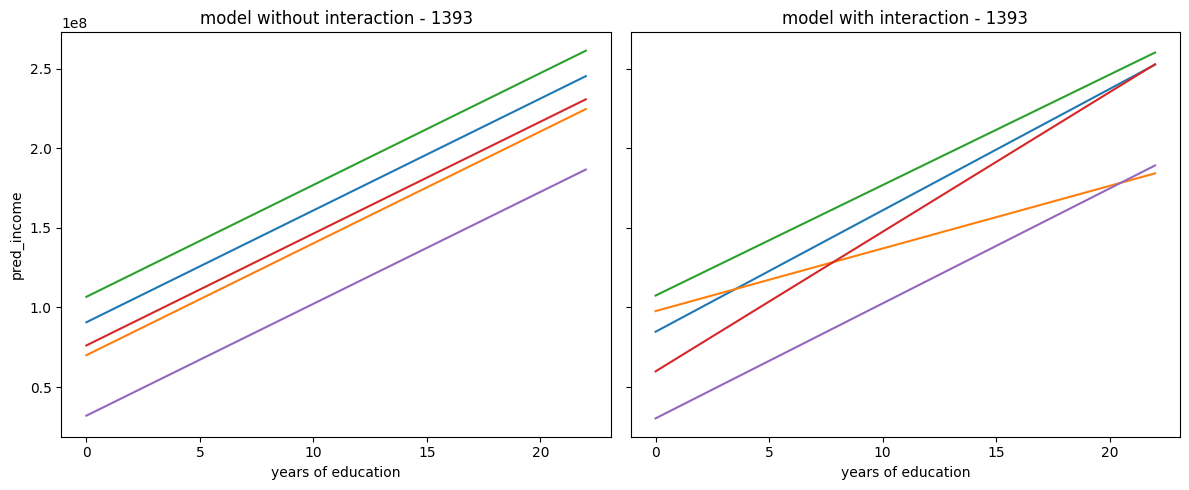

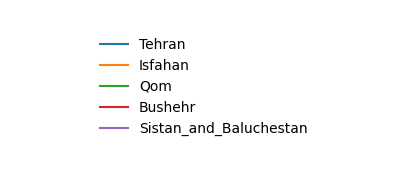


=== پردازش سال 1394 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.181
Model:                            OLS   Adj. R-squared:                  0.181
Method:                 Least Squares   F-statistic:                     227.6
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          5.24e-220
Time:                        02:29:57   Log-Likelihood:            -1.0165e+05
No. Observations:                5140   AIC:                         2.033e+05
Df Residuals:                    5134   BIC:                         2.033e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

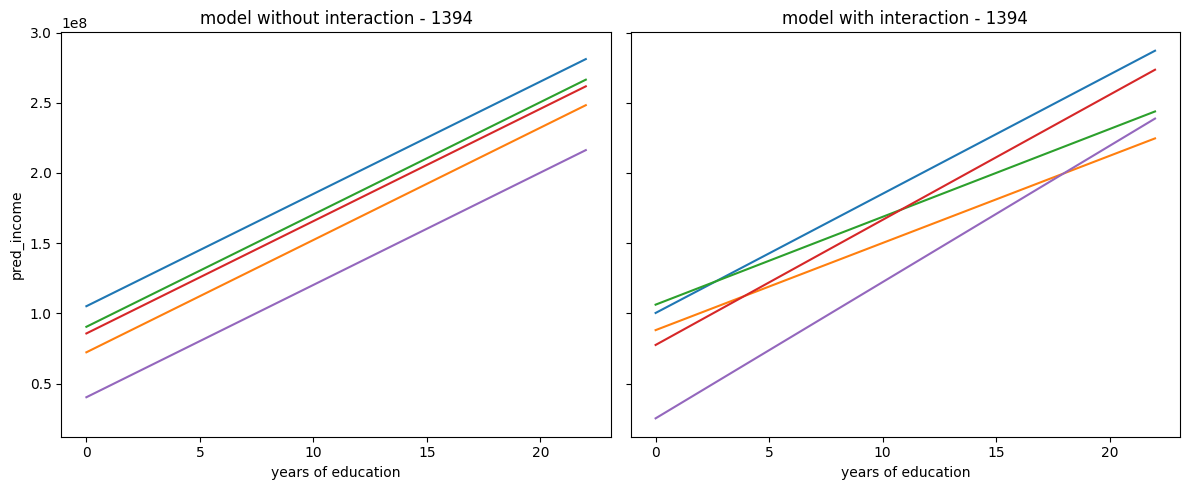

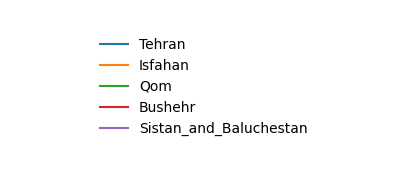


=== پردازش سال 1395 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.195
Model:                            OLS   Adj. R-squared:                  0.194
Method:                 Least Squares   F-statistic:                     248.6
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          1.58e-238
Time:                        02:30:04   Log-Likelihood:            -1.0277e+05
No. Observations:                5138   AIC:                         2.056e+05
Df Residuals:                    5132   BIC:                         2.056e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

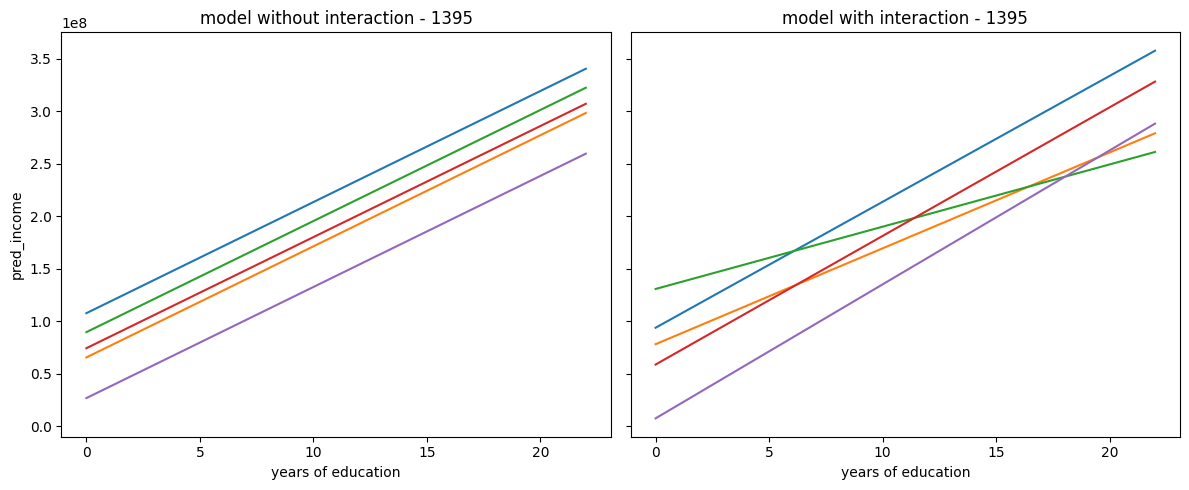

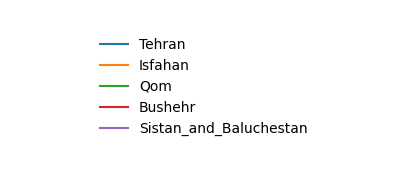


=== پردازش سال 1396 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.201
Model:                            OLS   Adj. R-squared:                  0.201
Method:                 Least Squares   F-statistic:                     258.1
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          1.08e-246
Time:                        02:30:14   Log-Likelihood:            -1.0325e+05
No. Observations:                5125   AIC:                         2.065e+05
Df Residuals:                    5119   BIC:                         2.066e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

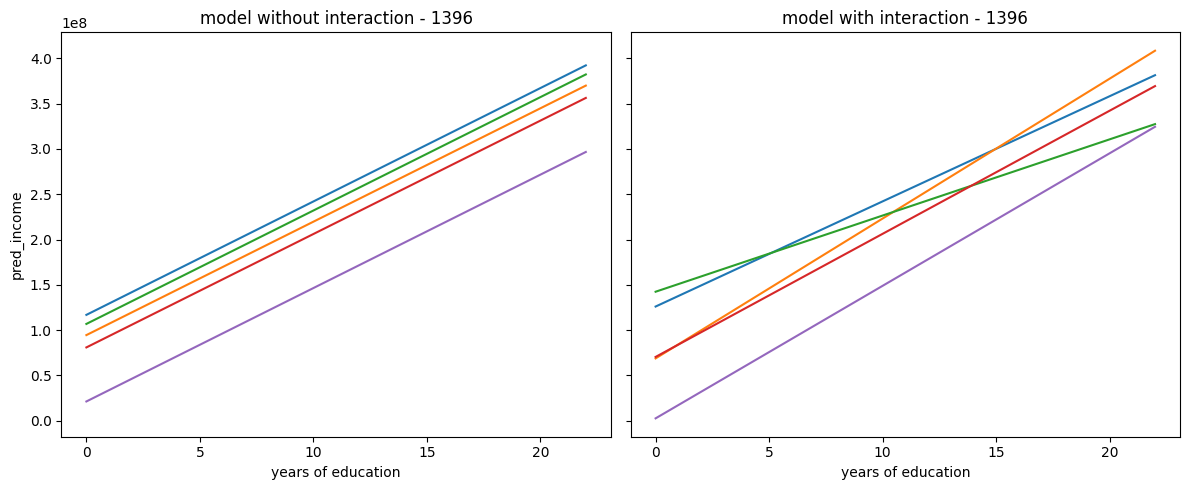

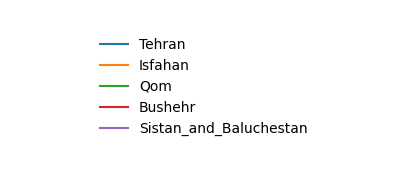


=== پردازش سال 1397 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.185
Model:                            OLS   Adj. R-squared:                  0.184
Method:                 Least Squares   F-statistic:                     243.9
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          2.11e-235
Time:                        02:30:24   Log-Likelihood:            -1.0930e+05
No. Observations:                5370   AIC:                         2.186e+05
Df Residuals:                    5364   BIC:                         2.186e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

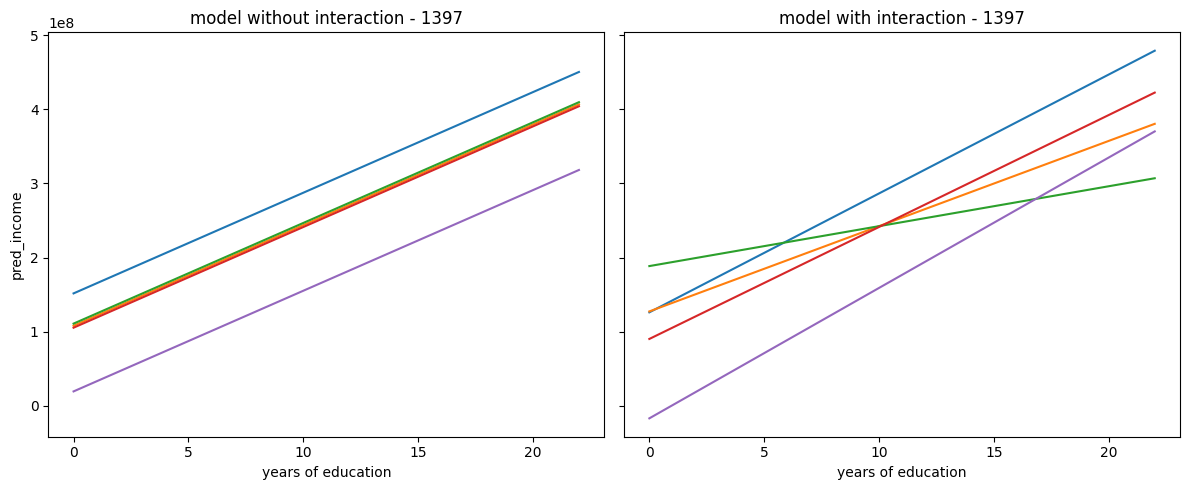

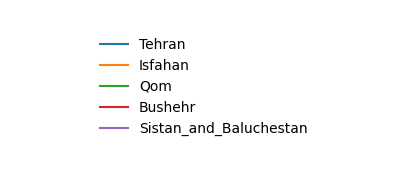


=== پردازش سال 1398 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.223
Model:                            OLS   Adj. R-squared:                  0.222
Method:                 Least Squares   F-statistic:                     302.0
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          5.43e-285
Time:                        02:30:34   Log-Likelihood:            -1.0774e+05
No. Observations:                5267   AIC:                         2.155e+05
Df Residuals:                    5261   BIC:                         2.155e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

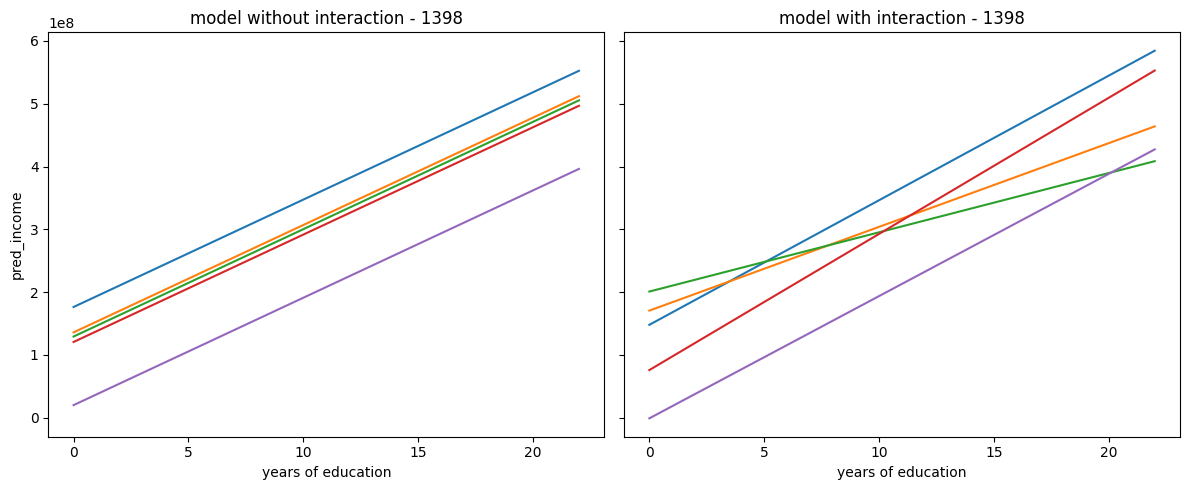

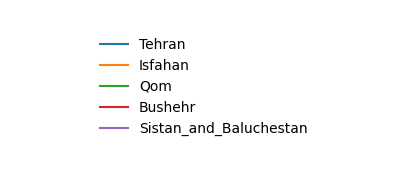


=== پردازش سال 1399 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.085
Model:                            OLS   Adj. R-squared:                  0.084
Method:                 Least Squares   F-statistic:                     98.75
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          7.30e-100
Time:                        02:30:43   Log-Likelihood:            -1.1436e+05
No. Observations:                5352   AIC:                         2.287e+05
Df Residuals:                    5346   BIC:                         2.288e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

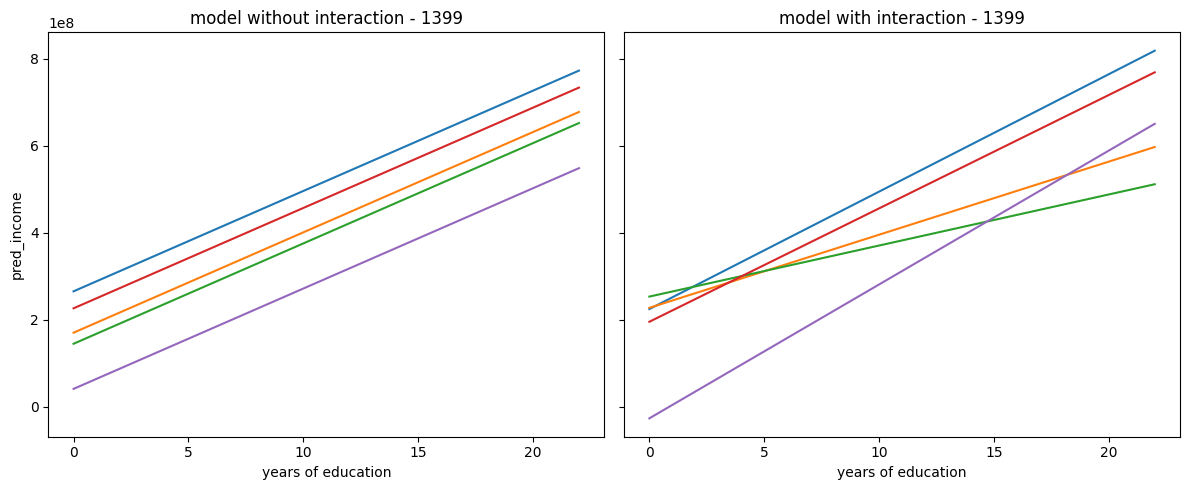

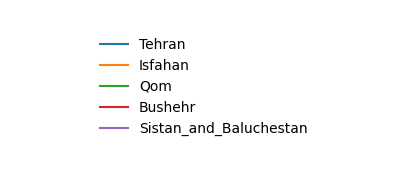


=== پردازش سال 1400 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.198
Model:                            OLS   Adj. R-squared:                  0.198
Method:                 Least Squares   F-statistic:                     258.1
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          3.50e-247
Time:                        02:30:53   Log-Likelihood:            -1.1083e+05
No. Observations:                5221   AIC:                         2.217e+05
Df Residuals:                    5215   BIC:                         2.217e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

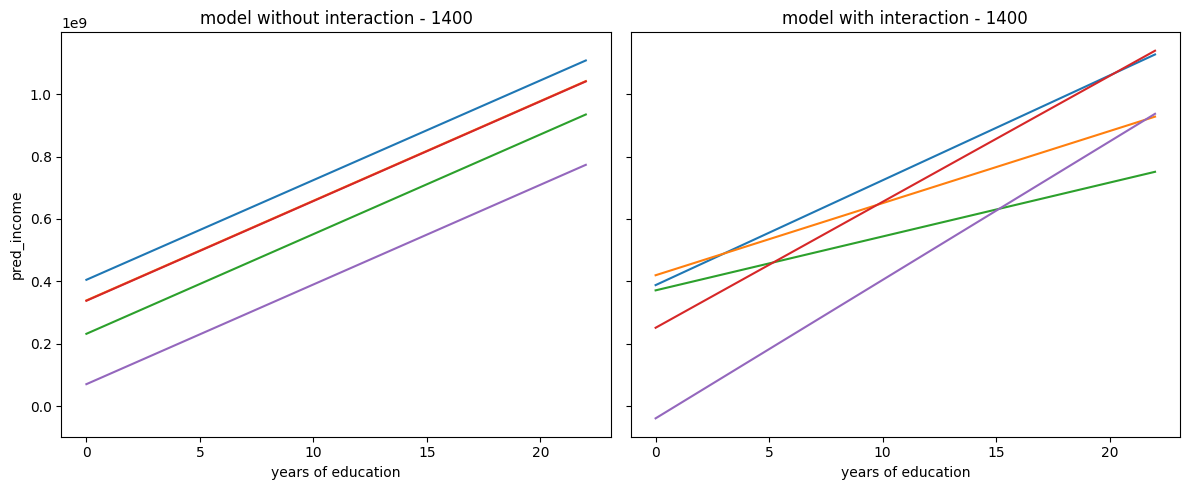

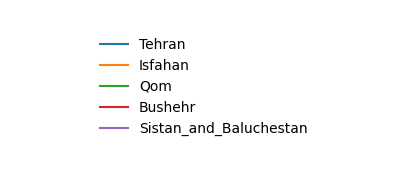


=== پردازش سال 1401 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.201
Model:                            OLS   Adj. R-squared:                  0.200
Method:                 Least Squares   F-statistic:                     262.6
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          4.09e-251
Time:                        02:31:06   Log-Likelihood:            -1.1246e+05
No. Observations:                5227   AIC:                         2.249e+05
Df Residuals:                    5221   BIC:                         2.250e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

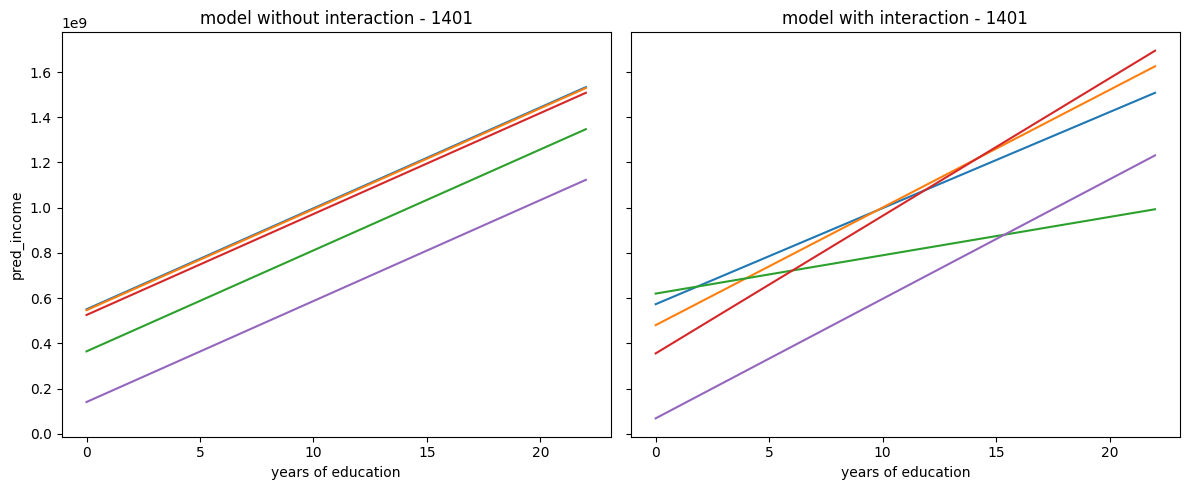

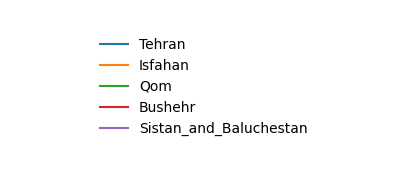


=== پردازش سال 1402 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.120
Model:                            OLS   Adj. R-squared:                  0.119
Method:                 Least Squares   F-statistic:                     141.0
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          1.48e-140
Time:                        02:31:16   Log-Likelihood:            -1.1488e+05
No. Observations:                5158   AIC:                         2.298e+05
Df Residuals:                    5152   BIC:                         2.298e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

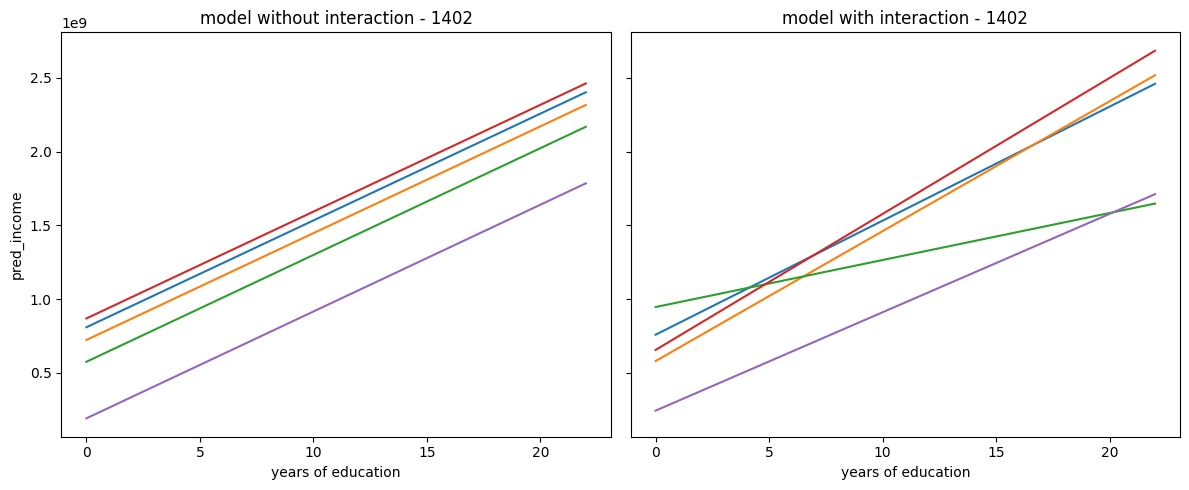

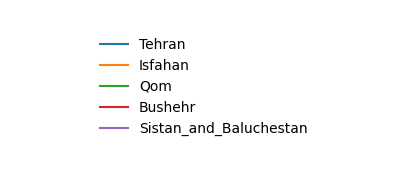

In [26]:
for year in range(1393, 1403):
    print(f"\n=== پردازش سال {year} ===")
    try:
        # ---------- بارگذاری داده‌ها ----------
        hbsir.setup(method="download_cleaned",download_source="mirror",years=[year])
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")

        hhinc = hbsir.load_table("Members_Total_Income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # ---------- پردازش ----------
        df = members[(members["Member_Number"] == 1) & 
                     (members["Education_Level"].isin(valid_levels))].copy()
        df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)

        df = df.merge(
            hhinc[hhinc["Member_Number"] == 1][["ID", "Income"]],
            on="ID", how="left"
        )

        urban_rural = table[["ID", "Urban_Rural"]].drop_duplicates()
        df = df.merge(urban_rural, on="ID", how="left")
        
        province_df = table[["ID", "Province"]].drop_duplicates()
        df = df.merge(province_df, on="ID", how="left")
        df = df.dropna(subset=["Income", "Province"])


        df = df.dropna(subset=["Income"])
        df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

                # ---------- مدل بر اساس استان (بدون/با تعامل) ----------
        # چند استان نماینده برای رسم (اگر نبودند از موجودها کامل می‌کنیم)
        pref_provinces = [
            "Tehran","Isfahan","Qom",
            "Bushehr",
            "Sistan_and_Baluchestan"]
        all_provs = df["Province"].dropna().unique().tolist()
        sel_provinces = [p for p in pref_provinces if p in all_provs]
        if len(sel_provinces) < 4:
            extra = [p for p in all_provs if p not in sel_provinces]
            sel_provinces.extend(extra[:max(0, 4 - len(sel_provinces))])

        dfp = df[df["Province"].isin(sel_provinces)].copy()
        if dfp.empty:
            raise ValueError("هیچ رکوردی برای استان‌های انتخابی در این سال وجود ندارد.")

        # مدل‌ها: شیب یکسان بین استان‌ها (بدون تعامل) vs شیب متفاوت به‌ازای هر استان (با تعامل)
        model_no_inter = smf.ols("Income ~ Years_Edu + C(Province)", data=dfp).fit()
        model_inter    = smf.ols("Income ~ Years_Edu * C(Province)", data=dfp).fit()

        print("\n---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل (وابسته = درآمد سرپرست) ----")
        print(model_inter.summary())

        # ---------- نمودار ----------
        years_range = np.linspace(dfp["Years_Edu"].min(), dfp["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, len(sel_provinces)),
            "Province":  np.repeat(sel_provinces, len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"]    = model_inter.predict(plot_df)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

        # روی خود نمودار legend نمی‌گذاریم؛ فقط label می‌دهیم تا بعداً legend جدا بسازیم
        for p in sel_provinces:
            sub = plot_df[plot_df["Province"] == p]
            axes[0].plot(sub["Years_Edu"], sub["pred_no_inter"], label=p)
            axes[1].plot(sub["Years_Edu"], sub["pred_inter"],    label=p)

        axes[0].set_title(f"model without interaction - {year}")
        axes[0].set_xlabel("years of education")
        axes[0].set_ylabel("pred_income")
        

        axes[1].set_title(f"model with interaction - {year}")
        axes[1].set_xlabel("years of education")
        

        # هندل/برچسب‌ها برای ساخت legend جدا
        handles, labels = axes[1].get_legend_handles_labels()

        plt.tight_layout()
        plt.show()

        # شکل جداگانه فقط برای legend
        fig_leg = plt.figure(figsize=(5, max(2, 0.25*len(labels))))
        fig_leg.legend(handles, labels, loc="center", ncol=1, frameon=False)
        plt.axis("off")
        plt.show()


    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue


## Province interactions: welfare



=== پردازش سال 1393 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.188
Model:                            OLS   Adj. R-squared:                  0.188
Method:                 Least Squares   F-statistic:                     241.2
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          2.76e-232
Time:                        02:33:51   Log-Likelihood:                 6381.2
No. Observations:                5199   AIC:                        -1.275e+04
Df Residuals:                    5193   BIC:                        -1.271e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

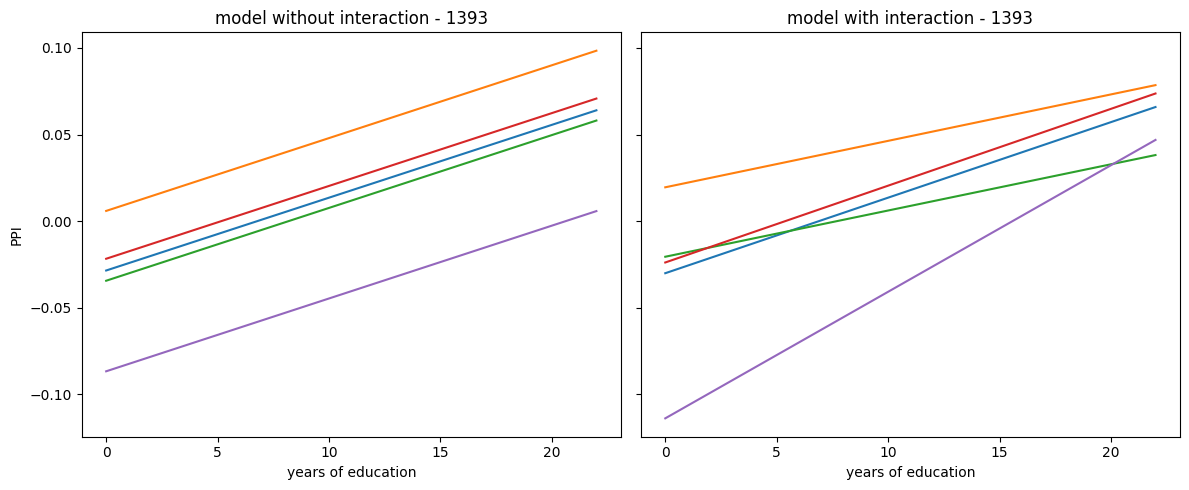

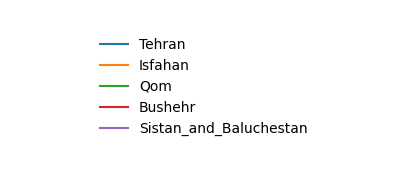


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1393
Sistan_and_Baluchestan    0.007303
Bushehr                   0.004432
Tehran                    0.004359
Isfahan                   0.002680
Qom                       0.002667
Name: Slope_by_Province_1393, dtype: float64

=== پردازش سال 1394 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.234
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     313.9
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          3.73e-294
Time:                        02:34:46   Log-Likelihood:                -4757.8
No. Observations:                5152   AIC:                             9528.
Df Residuals:                    5146   BIC:                             9567.
Df Model:                

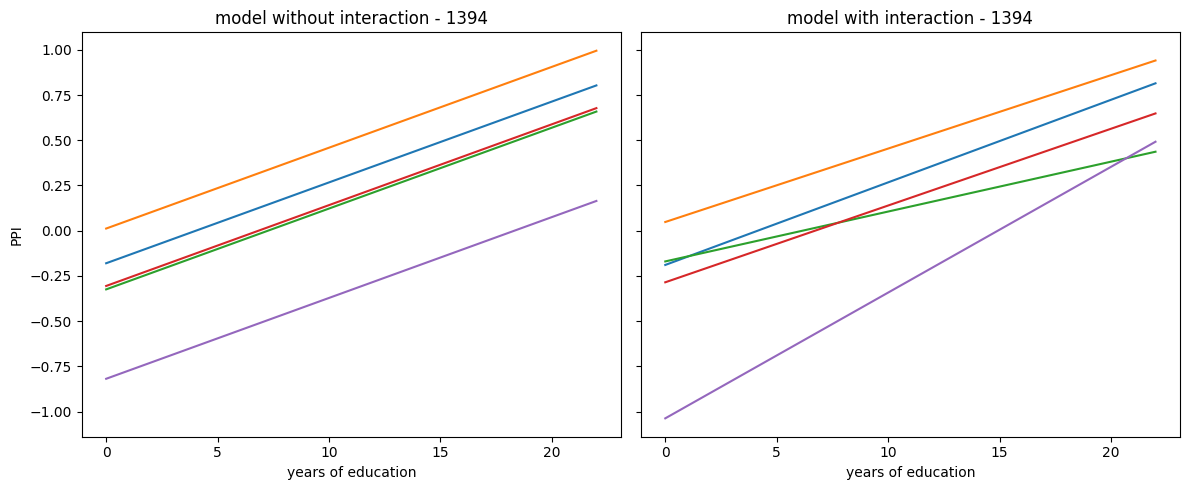

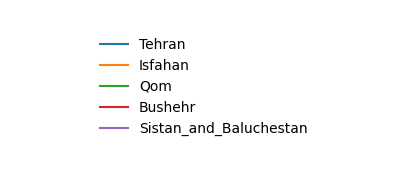


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1394
Sistan_and_Baluchestan    0.069505
Tehran                    0.045643
Bushehr                   0.042431
Isfahan                   0.040582
Qom                       0.027565
Name: Slope_by_Province_1394, dtype: float64

=== پردازش سال 1395 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.131
Model:                            OLS   Adj. R-squared:                  0.130
Method:                 Least Squares   F-statistic:                     155.0
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          7.19e-154
Time:                        02:35:41   Log-Likelihood:                -1297.7
No. Observations:                5156   AIC:                             2607.
Df Residuals:                    5150   BIC:                             2647.
Df Model:                

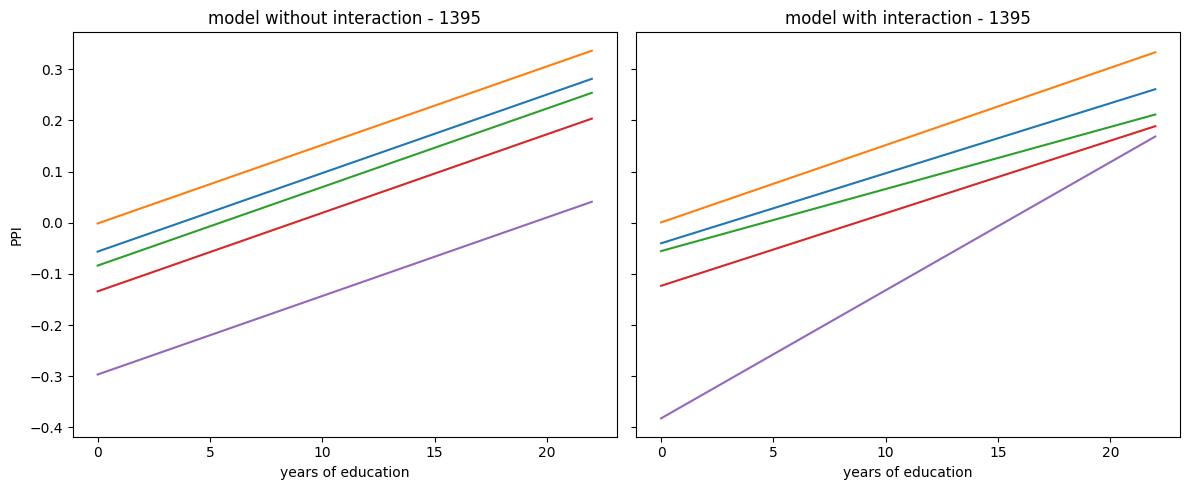

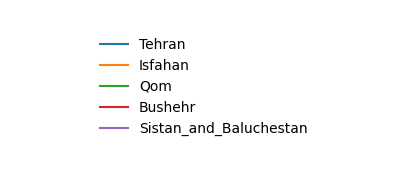


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1395
Sistan_and_Baluchestan    0.025031
Isfahan                   0.015109
Bushehr                   0.014175
Tehran                    0.013684
Qom                       0.012130
Name: Slope_by_Province_1395, dtype: float64

=== پردازش سال 1396 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.293
Model:                            OLS   Adj. R-squared:                  0.293
Method:                 Least Squares   F-statistic:                     426.5
Date:                Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                        02:36:27   Log-Likelihood:                -6139.4
No. Observations:                5139   AIC:                         1.229e+04
Df Residuals:                    5133   BIC:                         1.233e+04
Df Model:                

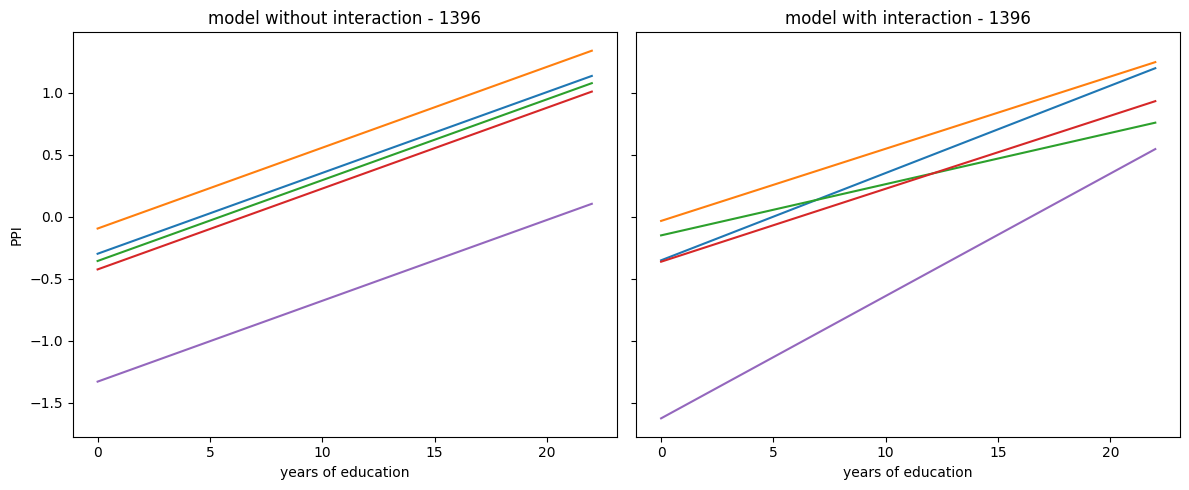

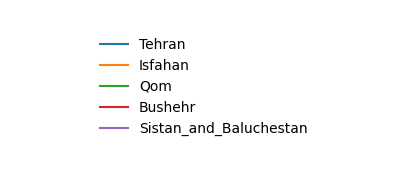


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1396
Sistan_and_Baluchestan    0.098704
Tehran                    0.070416
Bushehr                   0.058857
Isfahan                   0.058202
Qom                       0.041313
Name: Slope_by_Province_1396, dtype: float64

=== پردازش سال 1397 ===
⚠ خطا در پردازش سال 1397: File is not a zip file

=== پردازش سال 1398 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     4.396
Date:                Sat, 27 Sep 2025   Prob (F-statistic):           0.000537
Time:                        02:37:23   Log-Likelihood:                -9118.1
No. Observations:                5276   AIC:                         1.825e+04
Df Residuals:                 

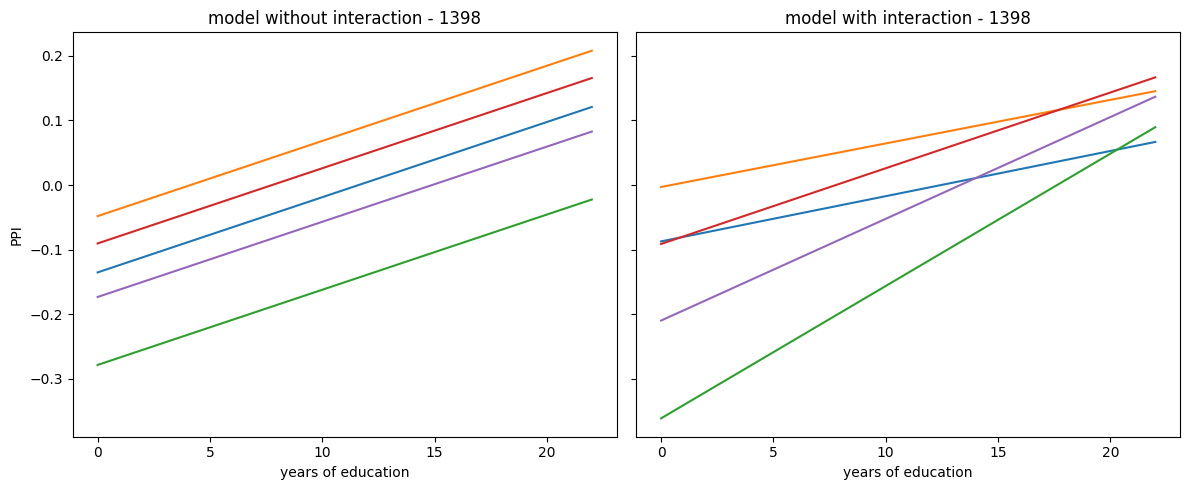

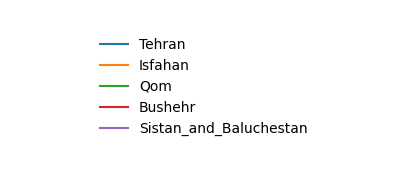


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1398
Qom                       0.020487
Sistan_and_Baluchestan    0.015751
Bushehr                   0.011722
Tehran                    0.006997
Isfahan                   0.006742
Name: Slope_by_Province_1398, dtype: float64

=== پردازش سال 1399 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.156
Model:                            OLS   Adj. R-squared:                  0.156
Method:                 Least Squares   F-statistic:                     198.5
Date:                Sat, 27 Sep 2025   Prob (F-statistic):          1.14e-194
Time:                        02:38:19   Log-Likelihood:                 803.69
No. Observations:                5363   AIC:                            -1595.
Df Residuals:                    5357   BIC:                            -1556.
Df Model:                

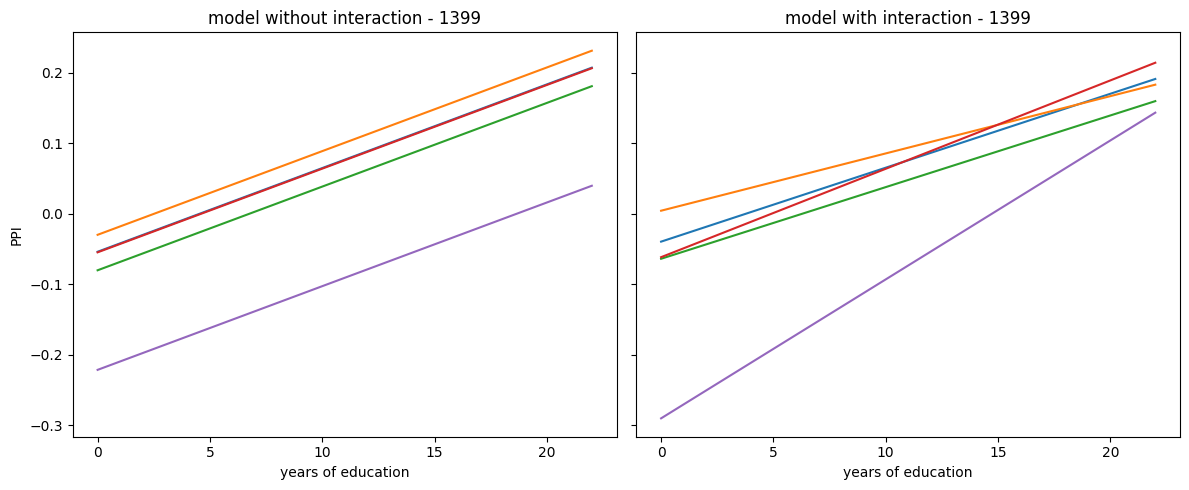

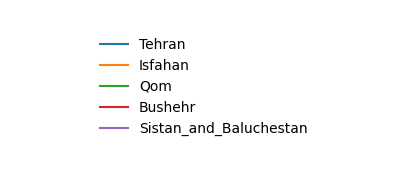


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1399
Sistan_and_Baluchestan    0.019714
Bushehr                   0.012540
Tehran                    0.010492
Qom                       0.010167
Isfahan                   0.008129
Name: Slope_by_Province_1399, dtype: float64

=== پردازش سال 1400 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.286
Model:                            OLS   Adj. R-squared:                  0.285
Method:                 Least Squares   F-statistic:                     418.4
Date:                Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                        02:39:11   Log-Likelihood:                -6909.4
No. Observations:                5230   AIC:                         1.383e+04
Df Residuals:                    5224   BIC:                         1.387e+04
Df Model:                

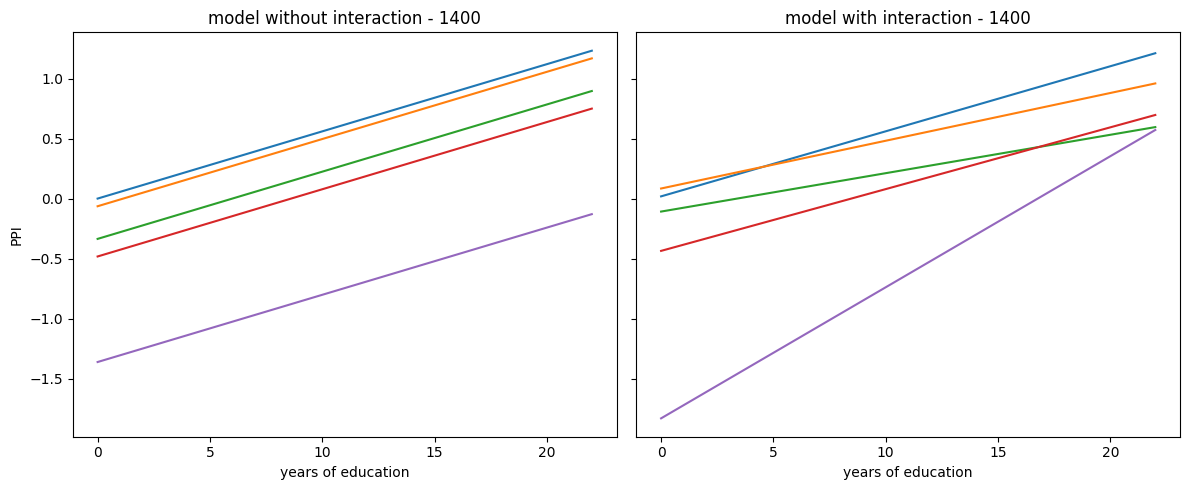

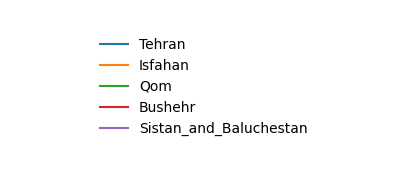


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1400
Sistan_and_Baluchestan    0.109178
Tehran                    0.054197
Bushehr                   0.051456
Isfahan                   0.039783
Qom                       0.031982
Name: Slope_by_Province_1400, dtype: float64

=== پردازش سال 1401 ===


C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20144\2006329225.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)
C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20144\2006329225.py:92: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})



---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.030
Model:                            OLS   Adj. R-squared:                  0.029
Method:                 Least Squares   F-statistic:                     31.88
Date:                Sat, 27 Sep 2025   Prob (F-statistic):           4.21e-32
Time:                        02:40:01   Log-Likelihood:                -5970.9
No. Observations:                5242   AIC:                         1.195e+04
Df Residuals:                    5236   BIC:                         1.199e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

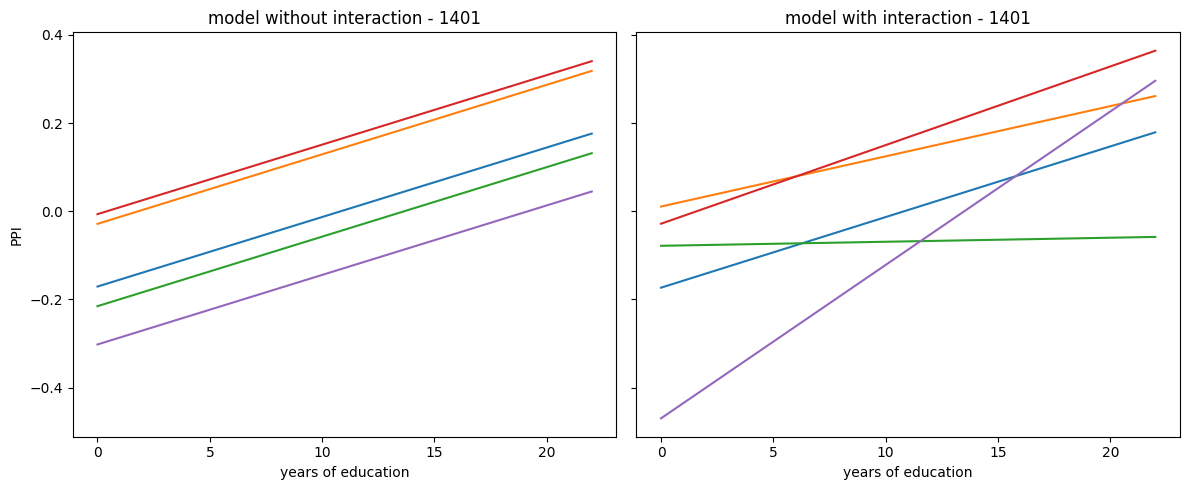

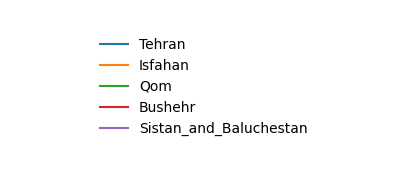


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1401
Sistan_and_Baluchestan    0.034777
Bushehr                   0.017825
Tehran                    0.016009
Isfahan                   0.011382
Qom                       0.000915
Name: Slope_by_Province_1401, dtype: float64


In [28]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

import hbsir
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ---------------------------
# Helpers
# ---------------------------
def winsorize(s, low_q=0.01, high_q=0.99):
    lo, hi = s.quantile(low_q), s.quantile(high_q)
    return s.clip(lower=lo, upper=hi)

def safe_log_series(s, eps=1.0):
    s = pd.to_numeric(s, errors="coerce").astype("float64")
    s = s.replace([np.inf, -np.inf], np.nan)
    s = s.clip(lower=eps)
    return np.log(s)

from pandas.api.types import is_numeric_dtype
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def cast_numeric(df: pd.DataFrame) -> pd.DataFrame:
    """هر ستونی که عددی باشد را به float64 استاندارد تبدیل می‌کند (رفع UInt8Dtype و ...)."""
    for c in df.columns:
        if is_numeric_dtype(df[c]):
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
    return df

def build_ppi_for_year(year):
    """PPI (PCA) را برای هر خانوار در سالِ ورودی می‌سازد و برمی‌گرداند."""
    hbsir.setup(years=[year])

    # --- Load
    exp = hbsir.load_table("Expenditures", years=[year])
    exp = hbsir.add_attribute(exp, name="Province")
    exp = hbsir.add_attribute(exp, name="County")
    exp = hbsir.add_attribute(exp, name="Urban_Rural")

    inc = hbsir.load_table("Members_Total_Income", years=[year])
    mem = hbsir.load_table("members_properties", years=[year])

    # --- Cast numeric to float64 (fix UInt8Dtype)
    exp = cast_numeric(exp)
    inc = cast_numeric(inc)
    mem = cast_numeric(mem)

    hh_key = "ID"

    # --- Category flags
    is_food = (exp.get("Table_Name", pd.Series(index=exp.index, dtype=object)) == "food")
    is_housing = (exp.get("Table_Name", pd.Series(index=exp.index, dtype=object)) == "home")

    # --- Regional price index (Province × Urban_Rural)
    price_df = exp.dropna(subset=["Price", "Commodity_Code"]).copy()
    nat_price = price_df.groupby("Commodity_Code")["Price"].median().rename("Nat_MedPrice")
    price_df = price_df.merge(nat_price, on="Commodity_Code", how="left")
    price_df = price_df[(price_df["Nat_MedPrice"] > 0) & (price_df["Price"] > 0)]
    price_df["RelPrice"] = price_df["Price"] / price_df["Nat_MedPrice"]
    price_df["Region"] = price_df["Province"].astype(str) + " | " + price_df["Urban_Rural"].astype(str)
    reg_item_rel = (price_df.groupby(["Region", "Commodity_Code"])["RelPrice"].median().reset_index())
    reg_pindex = (reg_item_rel.groupby("Region")["RelPrice"].median()
                  .rename("Region_PriceIndex").reset_index())

    exp["Region"] = exp["Province"].astype(str) + " | " + exp["Urban_Rural"].astype(str)
    exp = exp.merge(reg_pindex, on="Region", how="left")
    exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)

    # --- Real expenditures
    exp["Use_Exp"] = exp["Net_Expenditure"].fillna(exp["Gross_Expenditure"])
    exp["Real_Exp"] = exp["Use_Exp"] / exp["Region_PriceIndex"]

    hh_exp = exp.groupby(hh_key, as_index=False).agg(
        total_exp=("Use_Exp", "sum"),
        real_total_exp=("Real_Exp", "sum"),
        food_exp=("Use_Exp", lambda s: s[is_food.loc[s.index]].sum() if len(s) else 0.0),
        housing_exp=("Use_Exp", lambda s: s[is_housing.loc[s.index]].sum() if len(s) else 0.0),
    )
    hh_exp["food_share"]   = np.where(hh_exp["total_exp"]>0, hh_exp["food_exp"]/hh_exp["total_exp"], np.nan)
    hh_exp["rent_burden"]  = np.where(hh_exp["total_exp"]>0, hh_exp["housing_exp"]/hh_exp["total_exp"], np.nan)

    # --- Real income (sum all numeric cols safely)
    hh_inc = (inc.groupby("ID", as_index=False)["Income"]
            .sum()
            .rename(columns={"Income": "income_total"}))

    hh_region = exp[[hh_key, "Region"]].drop_duplicates()
    hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})
    hh_inc = hh_inc.merge(hh_region[[hh_key, "Region_PriceIndex"]], on=hh_key, how="left")
    hh_inc["Region_PriceIndex"] = hh_inc["Region_PriceIndex"].fillna(1.0)
    hh_inc["real_income"] = hh_inc["income_total"] / hh_inc["Region_PriceIndex"]

    # --- Household size & equivalence
    size = mem.groupby(hh_key).size().rename("hh_size").reset_index()
    if "Age" in mem.columns:
        tmp = mem[[hh_key, "Age"]].copy()
        tmp["is_child"] = (pd.to_numeric(tmp["Age"], errors="coerce") < 14).astype("int")
        children = tmp.groupby(hh_key)["is_child"].sum().rename("n_children").reset_index()
        demo = size.merge(children, on=hh_key, how="left").fillna({"n_children":0})
        demo["n_adults"] = (demo["hh_size"] - demo["n_children"]).clip(lower=0)
        demo["eq_size"]  = 1 + 0.5*np.maximum(demo["n_adults"]-1, 0) + 0.3*demo["n_children"]
        demo.loc[demo["eq_size"]<=0, "eq_size"] = demo["hh_size"].replace(0,1)
    else:
        demo = size.copy()
        demo["eq_size"] = np.sqrt(np.maximum(demo["hh_size"], 1))

    # --- Merge & features
    df = hh_exp.merge(hh_inc[[hh_key, "real_income"]], on=hh_key, how="left")
    df = df.merge(demo[[hh_key, "hh_size", "eq_size"]], on=hh_key, how="left")

    df["real_exp_pc"] = df["real_total_exp"] / df["eq_size"]
    df["real_inc_pc"] = df["real_income"]    / df["eq_size"]

    # پایداری
    df["real_exp_pc"] = winsorize(pd.to_numeric(df["real_exp_pc"], errors="coerce"))
    df["real_inc_pc"] = winsorize(pd.to_numeric(df["real_inc_pc"], errors="coerce"))

    df["log_real_exp_pc"] = safe_log_series(df["real_exp_pc"], eps=1.0)
    df["log_real_inc_pc"] = safe_log_series(df["real_inc_pc"], eps=1.0)

    df["one_minus_food"] = 1 - pd.to_numeric(df["food_share"],  errors="coerce")
    df["one_minus_rent"] = 1 - pd.to_numeric(df["rent_burden"], errors="coerce")

    feature_cols = ["log_real_exp_pc", "log_real_inc_pc", "one_minus_food", "one_minus_rent"]
    X = df[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(df[feature_cols].median())

    scaler = StandardScaler()
    X_std = scaler.fit_transform(X)

    pca = PCA(n_components=1, random_state=42)
    df["PPI_pca"]   = pca.fit_transform(X_std).ravel()
    df["PPI_pca_z"] = (df["PPI_pca"] - df["PPI_pca"].mean()) / df["PPI_pca"].std(ddof=0)
    df["PPI_score"] = 100 + 15*df["PPI_pca_z"]

    geo = exp[[hh_key, "Urban_Rural", "Province"]].drop_duplicates()
    df = df.merge(geo, on=hh_key, how="left")

    return df[[hh_key, "PPI_pca_z", "PPI_score", "Urban_Rural", "Province"]].drop_duplicates()



# ---------------------------
# نگاشت تحصیلات → سال‌های تحصیل (Fallback اگر نداشتی)
# ---------------------------
# اگر قبلاً valid_levels و edu_map را تعریف کرده‌ای، همین‌ها نادیده گرفته می‌شوند.
try:
    valid_levels  # type: ignore
    edu_map       # type: ignore
except NameError:
    valid_levels = [
    "Unofficial",             
    "Primary",                
    "Lower_Secondary",        
    "Higher_Secondary",       
    "Pre_University",         
    "Short_Cycle_Tertiary",   
    "Bachelors",              
    "Masters",                
    "Doctoral"                
    ]
    edu_map = {
    "Unofficial": 0,
    "Primary": 5,
    "Lower_Secondary": 8,
    "Higher_Secondary": 12,
    "Pre_University": 13,
    "Short_Cycle_Tertiary": 14,
    "Bachelors": 16,
    "Masters": 18,
    "Doctoral": 22
    }

# ---------------------------
# Loop: سال‌ها و مدل تعاملی با PPI
# ---------------------------
for year in range(1393, 1402):
    print(f"\n=== پردازش سال {year} ===")
    try:
        hbsir.setup(method="download_cleaned",download_source="mirror",years=[year])
        # داده‌ها
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")

        hhinc = hbsir.load_table("Members_Total_Income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # ساخت PPI
        ppi_df = build_ppi_for_year(year)  # ID, PPI_pca_z, PPI_score, Urban_Rural, Province

        # فیلتر سرپرست + نگاشت تحصیلات
        df = members[(members["Member_Number"] == 1)].copy()
        # اگر Education_Level متنی‌ست:
        if "Education_Level" in df.columns:
            df = df[df["Education_Level"].isin(valid_levels)].copy()
            df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)
        else:
            # اگر ستون سال تحصیل مستقیم داری:
            if "Years_Edu" not in df.columns:
                raise ValueError("ستون Education_Level یا Years_Edu در members_properties پیدا نشد.")
            df["Years_Edu"] = pd.to_numeric(df["Years_Edu"], errors="coerce")

        # الصاق Urban_Rural و PPI از ppi_df
        df = df.merge(ppi_df, on="ID", how="left")

        # سلامت داده
        df = df.dropna(subset=["Years_Edu", "PPI_pca_z", "Urban_Rural"])
        df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

               # ---------------- مدل‌ها و نمودار بر اساس استان ----------------
        # استان‌های منتخب برای رسم (اگر موجود نبودند، از استان‌های موجود پُر می‌کنیم)
        pref_provinces = [
            "Tehran","Isfahan","Qom",
            "Bushehr",
            "Sistan_and_Baluchestan"]

        all_provs = df["Province"].dropna().unique().tolist()
        sel_provinces = [p for p in pref_provinces if p in all_provs]
        if len(sel_provinces) < 4:
            # پُرکردن تا حداقل 4 استان
            extra = [p for p in all_provs if p not in sel_provinces]
            sel_provinces.extend(extra[:max(0, 4 - len(sel_provinces))])

        # فقط ردیف‌های استان‌های منتخب
        dfp = df[df["Province"].isin(sel_provinces)].copy()
        if dfp.empty:
            raise ValueError("هیچ رکوردی برای استان‌های انتخابی در این سال وجود ندارد.")

        # مدل بدون تعامل: شیب ثابت برای همه استان‌ها + عرض از مبدأ متفاوت
        model_no_inter = smf.ols("PPI_pca_z ~ Years_Edu + C(Province)", data=dfp).fit()
        # مدل با تعامل: شیب مجزا برای هر استان
        model_inter   = smf.ols("PPI_pca_z ~ Years_Edu * C(Province)", data=dfp).fit()

        print("\n---- مدل بدون تعامل (وابسته = PPI_pca_z) ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل (وابسته = PPI_pca_z) ----")
        print(model_inter.summary())

        # ---------------- گرید پیش‌بینی و رسم ----------------
        years_range = np.linspace(dfp["Years_Edu"].min(), dfp["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, len(sel_provinces)),
            "Province":  np.repeat(sel_provinces, len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"]    = model_inter.predict(plot_df)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

        # بدون legend روی نمودار (برای شلوغ نشدن)
        for p in sel_provinces:
            sub = plot_df[plot_df["Province"] == p]
            axes[0].plot(sub["Years_Edu"], sub["pred_no_inter"], label=p)
            axes[1].plot(sub["Years_Edu"], sub["pred_inter"],    label=p)
            # اسم استان را کنار انتهای خطِ پنل تعامل بنویس (خواناتر از legend)
            

        axes[0].set_title(f"model without interaction - {year}")
        axes[0].set_xlabel("years of education")
        axes[0].set_ylabel("PPI")
        

        axes[1].set_title(f"model with interaction - {year}")
        axes[1].set_xlabel("years of education")

        handles, labels = axes[1].get_legend_handles_labels()
        plt.tight_layout()
        plt.show()

        # ساخت legend در یک شکل جدا
        fig_leg = plt.figure(figsize=(5, max(2, 0.25*len(labels))))
        fig_leg.legend(handles, labels, loc="center", ncol=1, frameon=False)
        plt.axis("off")
        plt.show()


        # شیب هر استان در مدلِ تعاملی (کمک به تفسیر)
        base_slope = model_inter.params.get("Years_Edu", np.nan)
        slopes = {}
        for p in sel_provinces:
            term = f"Years_Edu:C(Province)[T.{p}]"
            slopes[p] = base_slope + model_inter.params.get(term, 0.0)
        slopes = pd.Series(slopes, name=f"Slope_by_Province_{year}").sort_values(ascending=False)
        print("\nشیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال", year)
        print(slopes)


    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue
